# AnteceDengue — AV1 revisada
**Entendimento, preparação e evidências para previsão territorial de notificações de dengue**

Erick Acioli Belo · CESAR School · Aprendizado de Máquina  
Professora Chaina Oliveira · Execução com fontes reais: 04/11/2026

**Objetivo:** investigar relações entre clima e notificações de dengue e preparar uma base reproduzível para prever registros da próxima semana por bairro, apoiando a futura priorização de ações preventivas.

**Estado desta versão:** correção da interrupção por IDs repetidos; cobertura explicitada como hipótese operacional; dados climáticos selecionados conforme medições válidas. As saídas registram a execução real realizada na revisão, sem treinamento de modelos. Conferir o resumo final para período, perdas e limitações.

**Feedback da AV1 (8/10):** segundo o aluno, organização, explicação e análise das novas features e aplicação/justificativa de normalização e padronização. Não há divisão oficial dos descontos. Não é possível garantir uma nota futura.

As saídas antigas foram removidas nesta cópia e o original foi preservado. A contagem representa notificações, sem afirmar confirmação clínica.

## 1. Problema, hipótese e continuidade
**AV1:** descrever padrões territoriais e temporais e investigar relações de chuva, temperatura e umidade com notificações posteriores.  
**AV2:** avaliar se essas informações permitem prever registros na próxima semana por bairro e se acrescentar clima melhora o desempenho fora do período de treinamento.  
**Aplicação proposta:** apoiar a identificação de áreas prioritárias para investigação e ações preventivas. Não há validação de impacto operacional neste trabalho.

Uma linha analítica representa um bairro e uma semana, de segunda a domingo. A data da notificação será convertida para esse calendário também usado no clima. Não chamamos esse calendário de semana epidemiológica oficial.

Associação municipal não comprova associação em cada bairro, causalidade, nem capacidade de previsão. Esses níveis serão distinguidos. O clima da estação A301 é compartilhado pelos bairros: não representa microclimas locais.

**Roteiro e critérios de conclusão**

| Requisito AV1 | Evidência nesta versão |
|---|---|
| Problema e aplicação | Objetivo, unidade bairro-semana, alvo e limites do uso |
| Dataset | Fontes, esquema, contagens por etapa, dicionário e tipos |
| EDA | Distribuições, ausências, correlações, outliers e interpretação guiada |
| Tratamento | Reconciliação de perdas, cobertura, junções, imputação, encoding e escala |
| Feature engineering | Fórmulas, motivo, disponibilidade e EDA específica |
| Documentação | Notebook, relatório e documentação de apoio |
| Descobertas | Resumo gerado somente após execução com fontes oficiais |

**Para considerar concluído:** cobertura aprovada, execução completa sem erro, perdas reconciliadas e interpretação humana das saídas. Código revisado sozinho não encerra a etapa.

## 2. Fontes oficiais

1. [Casos de Dengue, Zika e Chikungunya - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/casos-de-dengue-zika-e-chikungunya)
2. [Área urbana e limites dos bairros - Prefeitura do Recife](https://dados.recife.pe.gov.br/dataset/area-urbana)
3. [Agregados por bairro do Censo 2022 - IBGE](https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/)
4. [Dados históricos anuais - INMET](https://portal.inmet.gov.br/dadoshistoricos)

Os microdados de dengue possuem campos pessoais que não são necessários para esta análise. O notebook seleciona imediatamente apenas data, semana, ano, bairro e classificação, evitando utilizar endereço, CEP, nome de logradouro ou data de nascimento.

## 3. Configuração do ambiente

In [1]:
import io, json, re, zipfile, unicodedata, hashlib, platform
from pathlib import Path
from urllib.request import urlopen, Request
from urllib.error import URLError, HTTPError
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)
DATA_DIR = Path.cwd() / "dados_av1_revisada"
REPORT_DIR = DATA_DIR / "relatorios"
INPUT_DIR = Path.cwd() / "entradas_oficiais"
for d in [DATA_DIR, REPORT_DIR, INPUT_DIR]: d.mkdir(exist_ok=True)
ANOS = list(range(2016, 2026))
# Opcional: config_local.json com intervalos_cobertura_confirmada e anos.
CONFIG = json.loads(Path("config_local.json").read_text()) if Path("config_local.json").exists() else {}
ANOS = CONFIG.get("anos", ANOS)
# Hipótese operacional para arquivos históricos anuais, NÃO garantia de completude da vigilância.
# Datas reais dos arquivos foram conferidas, incluindo registros até 31/12/2025; cobertura continua uma hipótese da fonte anual.
INTERVALOS_COBERTURA_CONFIRMADA = CONFIG.get("intervalos_cobertura_confirmada", [("2016-01-01", "2025-12-31")])
JUSTIFICATIVA_COBERTURA = CONFIG.get("justificativa_cobertura", "Hipótese operacional: recursos oficiais anuais históricos de 2016–2025 representam o período anual de notificações publicado. Não comprova ausência de subnotificação ou falhas do sistema. Zeros significam ausência de registro na fonte sob essa hipótese. Foram conferidos registros de 2025 até 31/12/2025; não é garantia de completude de vigilância.")
ANOS_CLIMA = CONFIG.get("anos_clima", [a for a in ANOS if a <= 2021])
COBERTURA_MINIMA_CLIMA = float(CONFIG.get("cobertura_minima_clima", .90))
assert 0 < COBERTURA_MINIMA_CLIMA <= 1
CSV_CLIMA_LOCAL = INPUT_DIR / "clima_A301_horario.csv"
ATUALIZAR_CACHE = bool(CONFIG.get("atualizar_cache", False))
EXECUCAO_FONTES = []
RUN_INICIO = datetime.now(timezone.utc).isoformat()
print("Diretório:", DATA_DIR.resolve())
print("Não há dados de demonstração neste notebook. As entradas precisam ser oficiais.")
print("Cobertura adotada como hipótese operacional:", INTERVALOS_COBERTURA_CONFIRMADA)
print(JUSTIFICATIVA_COBERTURA)

Diretório: /content/dados_av1_revisada
Não há dados de demonstração neste notebook. As entradas precisam ser oficiais.
Cobertura adotada como hipótese operacional: [('2016-01-01', '2025-12-31')]
Hipótese operacional: recursos oficiais anuais históricos de 2016–2025 representam o período anual de notificações publicado. Não comprova ausência de subnotificação ou falhas do sistema. Zeros significam ausência de registro na fonte sob essa hipótese. Foram conferidos registros de 2025 até 31/12/2025; não é garantia de completude de vigilância.


## 4. Funções auxiliares

In [2]:
def sem_acentos(texto):
    texto = "" if pd.isna(texto) else str(texto)
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

def nome_padrao(texto):
    return re.sub(r"\s+", " ", sem_acentos(texto).upper().strip())

def coluna_padrao(texto):
    return re.sub(r"[^A-Z0-9]+", "_", nome_padrao(texto).lstrip("\ufeff")).strip("_")

def registrar_fonte(origem, payload):
    EXECUCAO_FONTES.append({"origem":str(origem),"sha256":hashlib.sha256(payload).hexdigest(),"bytes":len(payload)})
    return payload

def baixar(url, timeout=45):
    p = DATA_DIR / (hashlib.sha256(url.encode()).hexdigest() + ".bin")
    if p.exists() and not ATUALIZAR_CACHE:
        return registrar_fonte(url, p.read_bytes())
    try:
        with urlopen(Request(url, headers={"User-Agent":"AnteceDengue-academico/3"}), timeout=timeout) as r:
            payload = r.read()
    except (URLError, HTTPError, TimeoutError) as e:
        raise RuntimeError(f"Não foi possível baixar a fonte {url}. Use uma cópia oficial em entradas_oficiais. Erro: {e}") from e
    if payload.lstrip().lower().startswith((b"<!doctype html", b"<html")):
        raise ValueError("A fonte retornou HTML em vez dos dados; não foi guardada no cache.")
    temp = p.with_suffix(".tmp")
    temp.write_bytes(payload); temp.replace(p)
    return registrar_fonte(url, payload)

def ler_local(path):
    return registrar_fonte(path, Path(path).read_bytes())

def api_json(url):
    return json.loads(baixar(url))

def ler_csv_bytes(conteudo):
    erros = []
    for enc in ("utf-8-sig", "latin-1"):
        for sep in (";", ",", "\t"):
            try:
                df = pd.read_csv(io.BytesIO(conteudo), sep=sep, encoding=enc, dtype=str, low_memory=False)
                if len(df.columns) > 1:
                    df.columns = [coluna_padrao(c) for c in df.columns]
                    if df.columns.duplicated().any():
                        raise ValueError("Colunas repetidas depois da padronização")
                    return df
            except (UnicodeError, pd.errors.ParserError, pd.errors.EmptyDataError) as e:
                erros.append(str(e))
    raise ValueError("CSV sem estrutura tabular reconhecida; confira o recurso e o separador.")

ALIASES = {
 "NU_NOTIFIC": ["NU_NOTIFIC", "NUM_NOTIFIC", "NUMERO_NOTIFICACAO", "NU_NOTIFICACAO"],
 "DT_NOTIFIC": ["DT_NOTIFIC", "DATA_NOTIFICACAO", "DATA_DA_NOTIFICACAO", "DT_NOTIFICACAO"],
 "SEM_NOT": ["SEM_NOT", "SEMANA_NOTIFICACAO", "DS_SEMANA_NOTIFICACAO"],
 "NU_ANO": ["NU_ANO", "ANO", "NOTIFICACAO_ANO"],
 "ID_BAIRRO": ["ID_BAIRRO", "COD_BAIRRO", "CODIGO_BAIRRO", "CO_BAIRRO_RESIDENCIA"],
 "NM_BAIRRO": ["NM_BAIRRO", "BAIRRO", "NOME_BAIRRO", "NO_BAIRRO_RESIDENCIA"],
 "ID_MUNICIPIO_RESIDENCIA": ["ID_MUNICIPIO_RESIDENCIA", "ID_MN_RESI", "CO_MUNICIPIO_RESIDENCIA"],
 "CLASSI_FIN": ["CLASSI_FIN", "CLASSIFICACAO_FINAL", "TP_CLASSIFICACAO_FINAL"],
}

def selecionar_notificacoes(bruto, ano):
    escolhido = {}
    for destino, candidatos in ALIASES.items():
        existentes = [c for c in candidatos if c in bruto]
        if len(existentes) > 1:
            raise ValueError(f"{ano}: campos ambíguos para {destino}: {existentes}")
        if existentes:
            escolhido[existentes[0]] = destino
    if "DT_NOTIFIC" not in escolhido.values() or not ({"ID_BAIRRO", "NM_BAIRRO"} & set(escolhido.values())):
        raise ValueError(f"{ano}: esquema não reconhecido. Colunas: {bruto.columns.tolist()}")
    df = bruto[list(escolhido)].rename(columns=escolhido).copy()
    for c in ALIASES:
        if c not in df: df[c] = pd.NA
    df["ANO_ARQUIVO"] = ano
    return df

def inicio_semana(datas):
    datas = pd.to_datetime(datas)
    return datas.dt.normalize() - pd.to_timedelta(datas.dt.weekday, unit="D")

def semana_coberta(data):
    # Os sete dias precisam pertencer a intervalos aprovados, inclusive viradas de ano.
    dias = pd.date_range(pd.Timestamp(data), periods=7, freq="D")
    return all(any(pd.Timestamp(a) <= d <= pd.Timestamp(b) for a,b in INTERVALOS_COBERTURA_CONFIRMADA) for d in dias)

def datas_notificacao(valores):
    s = valores.astype("string").str.strip()
    # Aceita hora em timestamp oficial, preservando a data civil de notificação.
    iso = pd.to_datetime(s.str.extract(r"^(\d{4}-\d{2}-\d{2})", expand=False), format="%Y-%m-%d", errors="coerce")
    br = pd.to_datetime(s.str.extract(r"^(\d{2}/\d{2}/\d{4})", expand=False), format="%d/%m/%Y", errors="coerce")
    barras_iso = pd.to_datetime(s.str.extract(r"^(\d{4}/\d{2}/\d{2})", expand=False), format="%Y/%m/%d", errors="coerce")
    return iso.fillna(br).fillna(barras_iso)

def codigo_inteiro(serie):
    return serie.astype("string").str.strip().str.replace(r"\.0+$", "", regex=True).replace("", pd.NA)

def recurso_area(nome, formato):
    url = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=area-urbana"
    recursos = api_json(url)["result"]["resources"]
    candidatos = [r for r in recursos if nome in nome_padrao(r.get("name","")) and r.get("format", "").upper()==formato]
    if len(candidatos)!=1: raise ValueError(f"Recurso territorial ausente ou ambíguo: {nome}, {formato}")
    return candidatos[0]

## 5. Aquisição dos casos de dengue (2016-2025)

O Portal do Recife disponibiliza um CSV para cada ano. A API CKAN localiza os arquivos oficiais e o código os reúne automaticamente.

**Objetivo da etapa:** obter os microdados diretamente da fonte e manter somente as variáveis necessárias para a análise, reduzindo exposição de dados pessoais.

In [3]:
CKAN_DENGUE = "https://dados.recife.pe.gov.br/api/3/action/package_show?id=casos-de-dengue-zika-e-chikungunya"
recursos = None
bases, log = [], []
for ano in ANOS:
    local = INPUT_DIR / f"dengue_{ano}.csv"
    if local.exists():
        payload = ler_local(local); origem = str(local); titulo = local.name
    else:
        if recursos is None: recursos = api_json(CKAN_DENGUE)["result"]["resources"]
        candidatos = [r for r in recursos if re.search(rf"\b{ano}\b",r.get("name", "")) and "DENGUE" in nome_padrao(r.get("name", "")) and r.get("format", "").upper()=="CSV"]
        if len(candidatos)!=1: raise ValueError(f"{ano}: recurso ausente ou ambíguo; confira a seleção.")
        recurso = candidatos[0]
        payload = baixar(recurso["url"]); origem = recurso["url"]; titulo = recurso["name"]
    bruto = ler_csv_bytes(payload)
    base_ano = selecionar_notificacoes(bruto, ano)
    if base_ano.empty: raise ValueError(f"Arquivo {ano} vazio; não assumir zero notificações.")
    bases.append(base_ano)
    log.append({"ano":ano,"arquivo":titulo,"url":origem,"registros":len(base_ano),
      "colunas_originais":"|".join(bruto.columns),"sha256":hashlib.sha256(payload).hexdigest(),
      "datas_validas":int(datas_notificacao(base_ano.DT_NOTIFIC).notna().sum())})
    pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_por_ano.csv",index=False)
dengue = pd.concat(bases, ignore_index=True)
relatorio_download = pd.DataFrame(log)
display(relatorio_download)
assert relatorio_download.datas_validas.gt(0).all(), "Há um ano sem datas válidas; conferir o arquivo."
print("Linhas adquiridas:",len(dengue),"Colunas analíticas/controle:",dengue.shape[1])

,ano,arquivo,url,registros,colunas_originais,sha256,datas_validas
0,2016,Casos de Dengue em 2016,https://dados.recife.pe.gov.br:443/dataset/3c9...,18612,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,b3b8eaee8437ebcafbcb82fa1de19e944b376994855dba...,18612
1,2017,Casos de Dengue 2017,https://dados.recife.pe.gov.br:443/dataset/3c9...,2454,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,631db8367eec5e4c1cef2dae72b7504839ee4702413692...,2454
2,2018,Casos de Dengue 2018,https://dados.recife.pe.gov.br:443/dataset/3c9...,2687,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,cc0a826be0d71e00d04d4e39b8898c183656833e756c1d...,2687
3,2019,Casos de Dengue 2019,https://dados.recife.pe.gov.br:443/dataset/3c9...,7308,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,3eb0675c5093db8fba9bc34879a434b1e604ba24b16412...,7302
4,2020,Casos de Dengue 2020,https://dados.recife.pe.gov.br:443/dataset/3c9...,3540,NU_NOTIFICACAO|TP_NOTIFICACAO|CO_CID|DT_NOTIFI...,088c5e9edf26a6d82762bbb6896f85c02267c73ed2f1f1...,3540
5,2021,Casos de Dengue 2021,https://dados.recife.pe.gov.br:443/dataset/3c9...,10898,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,de41bea29614f26da3c22e7c1341d422e235311f75c303...,10898
6,2022,Casos de Dengue 2022,https://dados.recife.pe.gov.br:443/dataset/3c9...,2906,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,1d8846e400cd397c1ab659fdc20da865d2fd42015045f5...,2876
7,2023,Casos de Dengue 2023,https://dados.recife.pe.gov.br:443/dataset/3c9...,3523,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,529345732689e8c0ba8c0566f1b9a9446ef2a663262ecf...,3523
8,2024,Casos de Dengue 2024,https://dados.recife.pe.gov.br:443/dataset/3c9...,10548,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,44f5d1952d138b00d9bdacccbb3e913133c1f18ec7cd79...,10548
9,2025,Casos de Dengue 2025,https://dados.recife.pe.gov.br:443/dataset/3c9...,9187,NU_NOTIFIC|TP_NOT|ID_AGRAVO|DT_NOTIFIC|SEM_NOT...,b723a5f2186567e328377b83e733b2d88adb9f2d7d2e47...,9187


Linhas adquiridas: 71663 Colunas analíticas/controle: 9


**5.1 Dicionário das variáveis selecionadas**

Antes de analisar, precisamos saber o que cada coluna representa. Essa leitura define a granularidade original: **uma linha é uma notificação**.

In [4]:
dicionario = pd.DataFrame([
    ("NU_NOTIFIC", "Identificador da notificação", "Identificador"),
    ("DT_NOTIFIC", "Data da notificação", "Temporal"),
    ("SEM_NOT", "Ano e semana epidemiológica da notificação", "Temporal"),
    ("NU_ANO", "Ano registrado no sistema", "Temporal"),
    ("ID_BAIRRO", "Código do bairro", "Categórica nominal"),
    ("NM_BAIRRO", "Nome do bairro", "Categórica nominal"),
    ("CLASSI_FIN", "Classificação final do registro", "Categórica nominal"),
    ("ID_MUNICIPIO_RESIDENCIA", "Município de residência; controle territorial", "Categórica nominal"),
    ("ANO_ARQUIVO", "Ano do arquivo de origem", "Temporal/controle"),
], columns=["variavel", "significado", "tipo_conceitual"])

display(dicionario[dicionario["variavel"].isin(dengue.columns)])

,variavel,significado,tipo_conceitual
0,NU_NOTIFIC,Identificador da notificação,Identificador
1,DT_NOTIFIC,Data da notificação,Temporal
2,SEM_NOT,Ano e semana epidemiológica da notificação,Temporal
3,NU_ANO,Ano registrado no sistema,Temporal
4,ID_BAIRRO,Código do bairro,Categórica nominal
5,NM_BAIRRO,Nome do bairro,Categórica nominal
6,CLASSI_FIN,Classificação final do registro,Categórica nominal
7,ID_MUNICIPIO_RESIDENCIA,Município de residência; controle territorial,Categórica nominal
8,ANO_ARQUIVO,Ano do arquivo de origem,Temporal/controle


## 6. EDA inicial: estrutura e qualidade

**Pergunta:** como são os dados e quais problemas merecem tratamento?  
**Objetivo:** examinar dimensão, tipos, valores ausentes, cardinalidade, duplicidades e estatísticas descritivas antes de modificar a base.

In [5]:
print("Tipos originais:")
display(dengue.dtypes.to_frame("tipo"))

qualidade = pd.DataFrame({
    "tipo": dengue.dtypes.astype(str),
    "ausentes": dengue.isna().sum(),
    "percentual_ausente": (dengue.isna().mean() * 100).round(2),
    "valores_unicos": dengue.nunique(dropna=True),
}).sort_values("percentual_ausente", ascending=False)

display(qualidade)
print("Linhas iguais nos campos selecionados (não comprova duplicação de pessoas/eventos):", dengue.duplicated().sum())
print("\nResumo numérico:")
display(dengue.describe(include="all").T)
print("Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.")

Tipos originais:


,tipo
NU_NOTIFIC,object
DT_NOTIFIC,object
SEM_NOT,object
NU_ANO,object
ID_BAIRRO,object
NM_BAIRRO,object
ID_MUNICIPIO_RESIDENCIA,object
CLASSI_FIN,object
ANO_ARQUIVO,int64


,tipo,ausentes,percentual_ausente,valores_unicos
ID_BAIRRO,object,1163,1.62,197
NM_BAIRRO,object,487,0.68,138
CLASSI_FIN,object,316,0.44,12
NU_ANO,object,36,0.05,11
DT_NOTIFIC,object,36,0.05,3330
ID_MUNICIPIO_RESIDENCIA,object,36,0.05,2
SEM_NOT,object,36,0.05,523
NU_NOTIFIC,object,7,0.01,70804
ANO_ARQUIVO,int64,0,0.00,10


Linhas iguais nos campos selecionados (não comprova duplicação de pessoas/eventos): 8

Resumo numérico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
NU_NOTIFIC,71656,70804,3730241,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DT_NOTIFIC,71627,3330,2016-02-22,404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEM_NOT,71627,523,201607,1786,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NU_ANO,71627,11,2016,18538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_BAIRRO,70500,197,73,3224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NM_BAIRRO,71176,138,VARZEA,3579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ID_MUNICIPIO_RESIDENCIA,71627,2,261160,68105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CLASSI_FIN,71347,12,10,35978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ANO_ARQUIVO,71663.0,NaN,NaN,NaN,2020.291838,3.308664,2016.0,2016.0,2021.0,2024.0,2025.0


Objetivo cumprido: estrutura, tipos e problemas iniciais foram diagnosticados.


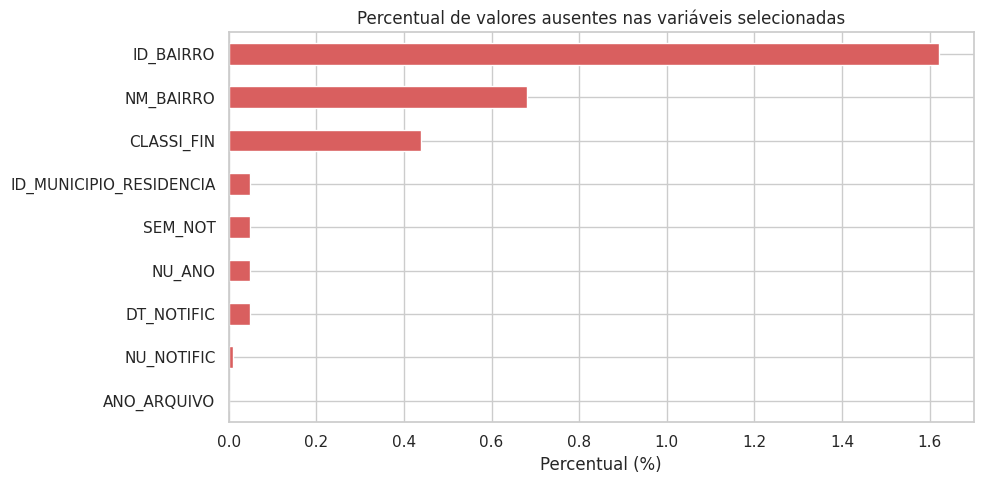

In [6]:
ax = qualidade["percentual_ausente"].sort_values().plot.barh(
    color="#d95f5f", figsize=(10, 5)
)
ax.set_title("Percentual de valores ausentes nas variáveis selecionadas")
ax.set_xlabel("Percentual (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Limpeza com reconciliação das perdas
Identificadores de notificação podem se repetir com informações distintas. A revisão inicial interrompia a execução nesses casos; o Colab enviado apresentou 789 IDs assim.

Agora preservamos os registros analiticamente distintos e removemos apenas cópias idênticas com identificador presente. IDs vazios permanecem preservados. O relatório agregado por ano informa os casos ambíguos, sem expor microdados nos resultados.

Não há evidência suficiente para escolher automaticamente uma versão ou tratar o ID isolado como chave única. Essa decisão evita perda silenciosa, mas pode manter revisões; a contagem é de registros publicados, não de pessoas ou episódios únicos. A sensibilidade a esses IDs precisa acompanhar a análise.

In [7]:
df = dengue.copy()
df["DT_NOTIFIC"] = datas_notificacao(df["DT_NOTIFIC"])
for c in ["ID_BAIRRO", "CLASSI_FIN"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
id_valido = codigo_inteiro(df["NU_NOTIFIC"])
df["NU_NOTIFIC"] = id_valido
com_id = df.loc[id_valido.notna()].copy()
chaves_id = ["ANO_ARQUIVO", "NU_NOTIFIC"]
campos = ["DT_NOTIFIC", "ID_BAIRRO", "NM_BAIRRO", "CLASSI_FIN", "ID_MUNICIPIO_RESIDENCIA"]
conflitos = com_id.groupby(chaves_id)[campos].nunique(dropna=False).gt(1).any(axis=1)
# Um identificador isolado não é uma chave única garantida. Preservar registros
# analiticamente distintos; remover só cópias idênticas com ID presente.
chaves_conflitantes = conflitos.loc[conflitos].reset_index()[chaves_id]
registros_divergentes = com_id.merge(chaves_conflitantes, on=chaves_id, how="inner")
resumo_conflitos = registros_divergentes.groupby("ANO_ARQUIVO").agg(
    ids_divergentes=("NU_NOTIFIC", "nunique"), registros_preservados=("NU_NOTIFIC", "size"))
resumo_conflitos.to_csv(REPORT_DIR/"ids_divergentes_resumo_por_ano.csv")
print("IDs com registros analíticos divergentes preservados:", int(conflitos.sum()))
display(resumo_conflitos)
duplicadas = df["NU_NOTIFIC"].notna() & df.duplicated(chaves_id + campos)
perdas_dup = df.loc[duplicadas].groupby("ANO_ARQUIVO").size()
df = df.loc[~duplicadas].copy()
arquivo_geo = INPUT_DIR / "bairros.geojson"
if arquivo_geo.exists(): geo_bairros = json.loads(ler_local(arquivo_geo))
else: geo_bairros = json.loads(baixar(recurso_area("BAIRROS DO RECIFE", "GEOJSON")["url"]))
mapa_id_bairro = {int(f["properties"]["CBAIRRCODI"]) // 10: nome_padrao(f["properties"]["EBAIRRNOME"]) for f in geo_bairros["features"]}
df["BAIRRO"] = df["ID_BAIRRO"].map(mapa_id_bairro).fillna(df["NM_BAIRRO"].map(nome_padrao))
df.loc[df["BAIRRO"].isin(["", "IGNORADO", "NAO INFORMADO"]), "BAIRRO"] = pd.NA
# Municípios de residência diferentes de Recife não entram na previsão territorial.
municipio = codigo_inteiro(df.ID_MUNICIPIO_RESIDENCIA)
fora_recife = municipio.notna() & ~municipio.isin(["261160", "2611606"])
sem_municipio = municipio.isna()
df["MUNICIPIO_RESIDENCIA_AUSENTE"] = sem_municipio
perdas_municipio = df.loc[fora_recife].groupby("ANO_ARQUIVO").size()
df = df.loc[~fora_recife].copy()
invalidas = df.loc[df[["DT_NOTIFIC", "BAIRRO"]].isna().any(axis=1)]
df_limpo = df.drop(index=invalidas.index).copy()
df_limpo["DATA_SEMANA"] = inicio_semana(df_limpo["DT_NOTIFIC"])
iso = df_limpo["DATA_SEMANA"].dt.isocalendar()
df_limpo["ANO"], df_limpo["SEMANA"] = iso.year.astype(int), iso.week.astype(int)
qualidade_ano = relatorio_download.set_index("ano")[["registros"]].rename(columns={"registros":"lidos"})
qualidade_ano["duplicatas_identicas_com_id"] = perdas_dup
qualidade_ano["fora_recife"] = perdas_municipio
qualidade_ano["chaves_invalidas"] = invalidas.groupby("ANO_ARQUIVO").size()
qualidade_ano["validos"] = df_limpo.groupby("ANO_ARQUIVO").size()
qualidade_ano = qualidade_ano.fillna(0).astype(int)
assert (qualidade_ano.lidos == qualidade_ano.duplicatas_identicas_com_id + qualidade_ano.fora_recife + qualidade_ano.chaves_invalidas + qualidade_ano.validos).all()
qualidade_ano.to_csv(REPORT_DIR / "qualidade_por_ano.csv")
display(qualidade_ano)
display(df_limpo.groupby(["ANO_ARQUIVO", "CLASSI_FIN"], dropna=False).size().rename("registros").reset_index())
print("IDs ausentes preservados:", int(df_limpo.NU_NOTIFIC.isna().sum()))
print("Registros distintos com o mesmo ID foram preservados. A contagem é de registros de notificação; não é contagem garantida de pessoas ou episódios únicos.")
print("Município de residência ausente nos registros mantidos:", int(df_limpo.MUNICIPIO_RESIDENCIA_AUSENTE.sum()))
print("Na ausência de município, o vínculo territorial depende da malha de bairros; é uma limitação explícita.")
datas_por_ano = df_limpo.groupby("ANO_ARQUIVO").DT_NOTIFIC.agg(["min","max","count"])
datas_por_ano.to_csv(REPORT_DIR/"datas_por_arquivo.csv")
display(datas_por_ano)
print("Limitação de identidade: a regra conservadora pode manter revisões do mesmo evento; não escolher arbitrariamente uma versão.")

IDs com registros analíticos divergentes preservados: 789


,ids_divergentes,registros_preservados
ANO_ARQUIVO,,
2016,533,1075
2017,14,28
2018,10,20
2019,80,162
2020,23,48
2021,29,58
2022,7,14
2023,11,24
2024,80,173


,lidos,duplicatas_identicas_com_id,fora_recife,chaves_invalidas,validos
ano,,,,,
2016,18612,0,0,338,18274
2017,2454,0,0,1,2453
2018,2687,0,0,8,2679
2019,7308,0,0,81,7227
2020,3540,0,0,10,3530
2021,10898,0,0,0,10898
2022,2906,3,0,27,2876
2023,3523,0,0,1,3522
2024,10548,0,0,0,10548


,ANO_ARQUIVO,CLASSI_FIN,registros
0,2016,1.0,3
1,2016,2.0,2
2,2016,5.0,4871
3,2016,8.0,1415
4,2016,10.0,11930
5,2016,11.0,28
6,2016,12.0,2
7,2016,NaN,23
8,2017,5.0,1487
9,2017,8.0,4


IDs ausentes preservados: 0
Registros distintos com o mesmo ID foram preservados. A contagem é de registros de notificação; não é contagem garantida de pessoas ou episódios únicos.
Município de residência ausente nos registros mantidos: 0
Na ausência de município, o vínculo territorial depende da malha de bairros; é uma limitação explícita.


,min,max,count
ANO_ARQUIVO,,,
2016,2016-01-03,2018-04-16,18274
2017,2017-01-02,2019-07-23,2453
2018,2018-01-02,2020-02-04,2679
2019,2019-01-02,2020-02-06,7227
2020,2020-01-01,2020-12-30,3530
2021,2021-01-01,2021-12-31,10898
2022,2022-01-03,2022-12-31,2876
2023,2023-01-01,2023-12-30,3522
2024,2024-01-02,2024-12-31,10548


Limitação de identidade: a regra conservadora pode manter revisões do mesmo evento; não escolher arbitrariamente uma versão.


## 8. Contagem por bairro e semana
Uma linha original é uma notificação; uma linha agregada é um bairro em uma semana. O nome `CASOS_SEMANAIS` é mantido para compatibilidade com a AV2, mas significa **registros de notificação**, não casos confirmados.

In [8]:
casos_semanais = df_limpo.groupby(["DATA_SEMANA", "BAIRRO"], as_index=False).size().rename(columns={"size":"REGISTROS_OBSERVADOS"})
assert casos_semanais.REGISTROS_OBSERVADOS.sum() == len(df_limpo)
display(casos_semanais.head())

,DATA_SEMANA,BAIRRO,REGISTROS_OBSERVADOS
0,2015-12-28,AFOGADOS,1
1,2015-12-28,BARRO,1
2,2015-12-28,BOA VIAGEM,1
3,2015-12-28,ILHA DO RETIRO,1
4,2015-12-28,MUSTARDINHA,1


## 9. População por bairro - Censo 2022/IBGE

In [9]:
local_pop = INPUT_DIR / "populacao_bairros.csv"
if local_pop.exists():
    pop_recife = pd.read_csv(io.BytesIO(ler_local(local_pop)))
    exigidas = {"BAIRRO", "POPULACAO_2022", "AREA_KM2_IBGE"}
    if not exigidas.issubset(pop_recife): raise ValueError(f"População local deve conter {exigidas}")
    pop_recife = pop_recife[list(sorted(exigidas))].copy()
else:
    URL_POPULACAO = "https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/Agregados_por_Bairro_xlsx/Agregados_por_bairros_basico_BR_20260520.zip"
    zip_local = INPUT_DIR / "populacao_ibge.zip"
    conteudo_zip = ler_local(zip_local) if zip_local.exists() else baixar(URL_POPULACAO)
    with zipfile.ZipFile(io.BytesIO(conteudo_zip)) as z:
        membros = [x for x in z.namelist() if x.lower().endswith(".xlsx")]
        if len(membros)!=1: raise ValueError("ZIP IBGE sem XLSX único: conferir a seleção.")
        populacao_br = pd.read_excel(io.BytesIO(z.read(membros[0])))
    pop_recife = populacao_br.loc[populacao_br.NM_UF.map(nome_padrao).eq("PERNAMBUCO") & populacao_br.NM_MUN.map(nome_padrao).eq("RECIFE")].copy()
    pop_recife = pop_recife.rename(columns={"v0001":"POPULACAO_2022","AREA_KM2":"AREA_KM2_IBGE"})[["BAIRRO" if "BAIRRO" in pop_recife else "NM_BAIRRO", "POPULACAO_2022", "AREA_KM2_IBGE"]]
    pop_recife = pop_recife.rename(columns={"NM_BAIRRO":"BAIRRO"})
pop_recife["BAIRRO"] = pop_recife.BAIRRO.map(nome_padrao)
# Compatibilizar o nome IBGE com a malha e a tabela RPA da Prefeitura.
# As duas fontes têm 94 bairros; este é o único nome divergente.
pop_recife["BAIRRO"] = pop_recife["BAIRRO"].replace({"SITIO DOS PINTOS - SAO BRAS":"SITIO DOS PINTOS"})
for c in ["POPULACAO_2022", "AREA_KM2_IBGE"]: pop_recife[c] = pd.to_numeric(pop_recife[c], errors="coerce")
assert pop_recife.POPULACAO_2022.gt(0).all() and pop_recife.AREA_KM2_IBGE.gt(0).all()
pop_recife["DENSIDADE_HAB_KM2"] = pop_recife.POPULACAO_2022 / pop_recife.AREA_KM2_IBGE
print("Bairros:",len(pop_recife),"População:",pop_recife.POPULACAO_2022.sum())
if len(pop_recife)!=94: print("ATENÇÃO: malha diferente dos 94 bairros esperados; conferir a fonte antes de concluir.")
display(pop_recife.head())

Bairros: 94 População: 1488920


,BAIRRO,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2
4281,RECIFE,541,1.235592,437.846797
4282,SANTO AMARO,27103,3.377832,8023.785433
4283,BOA VISTA,13147,1.769746,7428.748403
4284,SOLEDADE,2081,0.323412,6434.512984
4285,SANTO ANTONIO,447,0.517712,863.415075


## 10. RPA e geometria dos bairros - Prefeitura do Recife

In [10]:
local_rpa = INPUT_DIR / "bairros_rpa.csv"
rpa = ler_csv_bytes(ler_local(local_rpa) if local_rpa.exists() else baixar(recurso_area("BAIRROS E RPAS", "CSV")["url"]))
if not {"BAIRRO","RPA"}.issubset(rpa): raise ValueError("A tabela RPA precisa das colunas BAIRRO e RPA.")
rpa["BAIRRO"] = rpa.BAIRRO.map(nome_padrao)
rpa = rpa[["BAIRRO","RPA"]].drop_duplicates()
assert not rpa.BAIRRO.duplicated().any(), "RPA ambígua por bairro"
display(rpa.head())

,BAIRRO,RPA
0,AFLITOS,3
1,AFOGADOS,5
2,AGUA FRIA,2
3,ALTO DO MANDU,3
4,ALTO JOSE BONIFACIO,3


## 11. Painel semanal e hipótese de cobertura
O preenchimento com zero pressupõe que os recursos oficiais anuais históricos representam o período publicado. É uma hipótese operacional de cobertura da fonte, não comprovação de ausência de subnotificação ou falhas da vigilância.

A execução de referência utiliza 2016–2025 para essa hipótese; O arquivo de 2025 foi adquirido e suas datas foram conferidas até 31/12/2025. Semanas de fronteira incompletas ficam ausentes. A configuração permite alterar os intervalos ou deixá-los vazios para interromper a análise.

Os relatórios de datas e perdas devem acompanhar essa escolha. Ausência fora dos intervalos não vira zero. Para a comparação futura com clima, a elegibilidade depende também das medições efetivamente disponíveis.

In [11]:
assert not pop_recife.BAIRRO.duplicated().any(), "Bairros duplicados no IBGE"
assert pop_recife.POPULACAO_2022.gt(0).all() and pop_recife.AREA_KM2_IBGE.gt(0).all()
fora = casos_semanais.loc[~casos_semanais.BAIRRO.isin(pop_recife.BAIRRO)]
fora.to_csv(REPORT_DIR / "registros_fora_malha_agregados.csv", index=False)
print("Notificações fora da malha:", int(fora.REGISTROS_OBSERVADOS.sum()))
if INTERVALOS_COBERTURA_CONFIRMADA and not JUSTIFICATIVA_COBERTURA.strip():
    raise ValueError("Registre a justificativa documental da cobertura em config_local.json.")
inicio = pd.Timestamp(f"{min(ANOS)}-01-01")
fim = pd.Timestamp(f"{max(ANOS)}-12-31")
primeira = inicio - pd.Timedelta(days=inicio.weekday())
calendario = pd.DataFrame({"DATA_SEMANA": pd.date_range(primeira, fim, freq="W-MON")})
calendario["COBERTURA_DENGUE"] = calendario.DATA_SEMANA.map(semana_coberta)
iso = calendario.DATA_SEMANA.dt.isocalendar()
calendario["ANO"], calendario["SEMANA"] = iso.year.astype(int), iso.week.astype(int)
# Conferir também se os arquivos dos anos civis que cobrem cada semana foram adquiridos.
anos_lidos = set(relatorio_download.ano)
calendario["COBERTURA_DENGUE"] &= calendario.DATA_SEMANA.map(lambda d: all(x.year in anos_lidos for x in pd.date_range(d, periods=7)))
calendario.to_csv(REPORT_DIR / "cobertura_semanal.csv", index=False)
grade = pop_recife[["BAIRRO"]].merge(calendario, how="cross")
base = (grade.merge(casos_semanais, on=["DATA_SEMANA", "BAIRRO"], how="left", validate="one_to_one")
        .merge(pop_recife, on="BAIRRO", how="left", validate="many_to_one")
        .merge(rpa, on="BAIRRO", how="left", validate="many_to_one"))
base["CASOS_SEMANAIS"] = base.REGISTROS_OBSERVADOS.fillna(0).where(base.COBERTURA_DENGUE)
base["INCIDENCIA_100MIL"] = base.CASOS_SEMANAIS / base.POPULACAO_2022 * 100_000
assert not base.duplicated(["BAIRRO", "DATA_SEMANA"]).any()
print("Semanas cobertas pela hipótese operacional:", int(calendario.COBERTURA_DENGUE.sum()))
if not calendario.COBERTURA_DENGUE.any():
    raise ValueError("Cobertura ainda não aprovada. Confira relatorios/aquisicao_por_ano.csv e qualidade_por_ano.csv; preencha INTERVALOS_COBERTURA_CONFIRMADA na configuração e reexecute. Nenhum zero ou resultado climático foi validado.")
display(base.head())
perdas_territorio = pd.DataFrame({"indicador":["notificacoes_validas", "fora_malha", "no_painel_observado", "sem_rpa"],
 "valor":[len(df_limpo),int(fora.REGISTROS_OBSERVADOS.sum()),int(base.REGISTROS_OBSERVADOS.sum()),int(base.RPA.isna().sum())]})
assert len(df_limpo)==int(fora.REGISTROS_OBSERVADOS.sum())+int(base.REGISTROS_OBSERVADOS.sum())
perdas_territorio.to_csv(REPORT_DIR/"integracao_territorial.csv",index=False)

Notificações fora da malha: 49
Semanas cobertas pela hipótese operacional: 521


,BAIRRO,DATA_SEMANA,COBERTURA_DENGUE,ANO,SEMANA,REGISTROS_OBSERVADOS,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,CASOS_SEMANAIS,INCIDENCIA_100MIL
0,RECIFE,2015-12-28,False,2015,53,NaN,541,1.235592,437.846797,1,NaN,NaN
1,RECIFE,2016-01-04,True,2016,1,2.0,541,1.235592,437.846797,1,2.0,369.685767
2,RECIFE,2016-01-11,True,2016,2,3.0,541,1.235592,437.846797,1,3.0,554.528651
3,RECIFE,2016-01-18,True,2016,3,12.0,541,1.235592,437.846797,1,12.0,2218.114603
4,RECIFE,2016-01-25,True,2016,4,15.0,541,1.235592,437.846797,1,15.0,2772.643253


## 12. Dados climáticos do INMET

Os ZIPs anuais do INMET contêm todas as estações automáticas do Brasil. A célula abaixo baixa cada ano, seleciona somente a estação **A301 - Recife** e resume as observações horárias por semana.

> Esta célula pode levar alguns minutos porque os arquivos anuais são grandes. Os dados automáticos são brutos e podem apresentar `9999`, valores nulos ou falhas de sensores; essas ocorrências serão tratadas como ausentes.

In [12]:
def escolher_coluna(colunas, termos):
    return next((c for c in colunas if all(t in nome_padrao(c) for t in termos)), None)

def ler_csv_inmet(payload):
    texto = payload.decode("utf-8-sig", errors="replace")
    if "\ufffd" in texto: texto = payload.decode("latin-1")
    linhas = texto.splitlines()
    cabecalho = next((i for i,l in enumerate(linhas) if "DATA" in nome_padrao(l.split(";")[0]) and ";" in l and "HORA" in nome_padrao(l)),None)
    if cabecalho is None: raise ValueError("Cabeçalho horário do INMET não encontrado.")
    d = pd.read_csv(io.StringIO("\n".join(linhas[cabecalho:])), sep=";", decimal=",", dtype=str)
    data = escolher_coluna(d.columns,["DATA"]); hora = escolher_coluna(d.columns,["HORA"])
    medidas = {"PRECIPITACAO_MM":escolher_coluna(d.columns,["PRECIPITACAO","TOTAL"]),
     "TEMPERATURA_C":escolher_coluna(d.columns,["TEMPERATURA DO AR","BULBO SECO"]),
     "UMIDADE_PCT":escolher_coluna(d.columns,["UMIDADE RELATIVA DO AR","HORARIA"])}
    if not data or not hora or not all(medidas.values()): raise ValueError("Colunas do INMET não reconhecidas.")
    h = d[hora].astype(str).str.extract(r"^(\d{2})(?:\d{2}|:\d{2})?",expand=False)
    t = pd.DataFrame({"DATA_HORA_UTC":datas_notificacao(d[data]) + pd.to_timedelta(pd.to_numeric(h,errors="coerce"),unit="h")})
    for destino,origem in medidas.items():
        t[destino] = pd.to_numeric(d[origem].str.replace(",",".",regex=False),errors="coerce")
    return t

def carregar_inmet_recife(anos=None, estacao="A301"):
    anos = ANOS_CLIMA if anos is None else anos
    if CSV_CLIMA_LOCAL.exists():
        local = pd.read_csv(io.BytesIO(ler_local(CSV_CLIMA_LOCAL)))
        exigidas = ["DATA_HORA_UTC","PRECIPITACAO_MM","TEMPERATURA_C","UMIDADE_PCT"]
        if not set(exigidas).issubset(local): raise ValueError(f"Clima local deve conter {exigidas}")
        return local[exigidas].copy()
    partes, log = [], []
    for ano in anos:
        csv_local = INPUT_DIR / f"INMET_A301_{ano}.csv"
        if csv_local.exists():
            partes.append(ler_csv_inmet(ler_local(csv_local))); log.append({"ano":ano,"status":"csv_oficial_local"})
            continue
        zip_local = INPUT_DIR / f"INMET_{ano}.zip"
        payload = ler_local(zip_local) if zip_local.exists() else baixar(f"https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip")
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            membros = [x for x in z.namelist() if re.search(rf"(?:^|_){estacao}(?:_|\.)",nome_padrao(Path(x).name)) and x.lower().endswith(".csv")]
            if not membros:
                log.append({"ano":ano,"status":"estacao_nao_encontrada"})
            else:
                # Suporta um ano dividido em vários CSVs; horas repetidas serão conferidas depois.
                for m in membros: partes.append(ler_csv_inmet(z.read(m)))
                log.append({"ano":ano,"status":"encontrada","arquivos":len(membros)})
        pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_clima.csv",index=False)
    pd.DataFrame(log).to_csv(REPORT_DIR/"aquisicao_clima.csv",index=False)
    if not partes: raise ValueError("Nenhuma observação da A301 disponível. Não é possível analisar a hipótese climática.")
    return pd.concat(partes,ignore_index=True)

**12.1 Download dos anos e seleção da estação**

Esta célula é separada porque concentra a etapa mais demorada. O log mostra claramente quais anos possuem a estação A301 no arquivo anual. Ausência de uma estação em determinado ano é mantida como limitação, nunca inventada ou imputada sem justificativa.

In [13]:
clima_horario = carregar_inmet_recife()
clima_horario["DATA_HORA_UTC"] = pd.to_datetime(clima_horario.DATA_HORA_UTC, utc=True, errors="coerce")
clima_horario = clima_horario.dropna(subset=["DATA_HORA_UTC"]).sort_values("DATA_HORA_UTC")
medidas = ["PRECIPITACAO_MM", "TEMPERATURA_C", "UMIDADE_PCT"]
conflitos_hora = clima_horario.groupby("DATA_HORA_UTC")[medidas].nunique(dropna=False).gt(1).any(axis=1)
if conflitos_hora.any(): raise ValueError("Observações climáticas conflitantes para a mesma hora; revisar fontes.")
clima_horario = clima_horario.drop_duplicates("DATA_HORA_UTC")
for c in ["PRECIPITACAO_MM", "TEMPERATURA_C", "UMIDADE_PCT"]:
    clima_horario[c] = pd.to_numeric(clima_horario[c], errors="coerce")
    clima_horario.loc[clima_horario[c].abs().ge(9999), c] = np.nan
clima_horario.loc[clima_horario.PRECIPITACAO_MM.lt(0), "PRECIPITACAO_MM"] = np.nan
clima_horario.loc[~clima_horario.UMIDADE_PCT.between(0,100), "UMIDADE_PCT"] = np.nan
clima_horario["DATA_LOCAL"] = clima_horario.DATA_HORA_UTC.dt.tz_convert("America/Recife").dt.tz_localize(None).dt.normalize()
clima_horario["DATA_SEMANA"] = inicio_semana(clima_horario.DATA_LOCAL)
display(clima_horario.head())
# Contar linhas não é comprovar medições: conferir valores válidos por ano UTC.
qualidade_clima = clima_horario.assign(ANO_UTC=clima_horario.DATA_HORA_UTC.dt.year).groupby("ANO_UTC").agg(
    linhas_horarias=("DATA_HORA_UTC","size"),chuva_valida=("PRECIPITACAO_MM","count"),
    temperatura_valida=("TEMPERATURA_C","count"),umidade_valida=("UMIDADE_PCT","count"))
qualidade_clima.to_csv(REPORT_DIR/"qualidade_clima_por_ano.csv")
display(qualidade_clima)
if qualidade_clima[["chuva_valida","temperatura_valida","umidade_valida"]].eq(0).any(axis=None):
    print("Há ano/variável sem medições válidas; não equivale a ausência de chuva ou estabilidade do clima.")


,DATA_HORA_UTC,PRECIPITACAO_MM,TEMPERATURA_C,UMIDADE_PCT,DATA_LOCAL,DATA_SEMANA
0,2016-01-01 00:00:00+00:00,0.0,25.7,70.0,2015-12-31,2015-12-28
1,2016-01-01 01:00:00+00:00,0.0,25.2,75.0,2015-12-31,2015-12-28
2,2016-01-01 02:00:00+00:00,0.0,25.0,78.0,2015-12-31,2015-12-28
3,2016-01-01 03:00:00+00:00,0.0,25.0,78.0,2016-01-01,2015-12-28
4,2016-01-01 04:00:00+00:00,0.0,24.3,78.0,2016-01-01,2015-12-28


,linhas_horarias,chuva_valida,temperatura_valida,umidade_valida
ANO_UTC,,,,
2016,8784,8507,8507,8502
2017,8760,8226,8227,8087
2018,8760,8289,8289,8289
2019,8760,8755,8755,8755
2020,8784,8776,8776,8776
2021,8760,7492,7551,7442


In [14]:
clima_semanal = clima_horario.groupby("DATA_SEMANA").agg(
    PRECIPITACAO_SEMANAL_MM=("PRECIPITACAO_MM", lambda s:s.sum(min_count=1)),
    TEMPERATURA_MEDIA_C=("TEMPERATURA_C", "mean"), UMIDADE_MEDIA_PCT=("UMIDADE_PCT", "mean"),
    HORAS_CHUVA=("PRECIPITACAO_MM", "count"), HORAS_TEMPERATURA=("TEMPERATURA_C", "count"),
    HORAS_UMIDADE=("UMIDADE_PCT", "count"))
# Reindexar antes das janelas: uma linha sempre corresponde a sete dias consecutivos.
clima_semanal = clima_semanal.reindex(pd.DatetimeIndex(calendario.DATA_SEMANA, name="DATA_SEMANA"))
for medida, horas in [("PRECIPITACAO_SEMANAL_MM","HORAS_CHUVA"), ("TEMPERATURA_MEDIA_C","HORAS_TEMPERATURA"), ("UMIDADE_MEDIA_PCT","HORAS_UMIDADE")]:
    cobertura = "COBERTURA_" + horas.removeprefix("HORAS_")
    clima_semanal[cobertura] = clima_semanal[horas].fillna(0) / 168
    clima_semanal.loc[clima_semanal[cobertura] < COBERTURA_MINIMA_CLIMA, medida] = np.nan
# Chuva é soma observada, sem extrapolar horas faltantes. Limiar de 90% é decisão operacional a avaliar.
clima_semanal["CHUVA_4S_MM"] = clima_semanal.PRECIPITACAO_SEMANAL_MM.rolling(4, min_periods=4).sum()
clima_semanal = clima_semanal.reset_index()
clima_semanal.to_csv(REPORT_DIR / "clima_semanal_cobertura.csv", index=False)
base = base.merge(clima_semanal, on="DATA_SEMANA", how="left", validate="many_to_one")
display(base.head())

,BAIRRO,DATA_SEMANA,COBERTURA_DENGUE,ANO,SEMANA,REGISTROS_OBSERVADOS,POPULACAO_2022,AREA_KM2_IBGE,DENSIDADE_HAB_KM2,RPA,CASOS_SEMANAIS,INCIDENCIA_100MIL,PRECIPITACAO_SEMANAL_MM,TEMPERATURA_MEDIA_C,UMIDADE_MEDIA_PCT,HORAS_CHUVA,HORAS_TEMPERATURA,HORAS_UMIDADE,COBERTURA_CHUVA,COBERTURA_TEMPERATURA,COBERTURA_UMIDADE,CHUVA_4S_MM
0,RECIFE,2015-12-28,False,2015,53,NaN,541,1.235592,437.846797,1,NaN,NaN,NaN,NaN,NaN,75.0,75.0,75.0,0.446429,0.446429,0.446429,NaN
1,RECIFE,2016-01-04,True,2016,1,2.0,541,1.235592,437.846797,1,2.0,369.685767,32.0,27.047561,73.926829,164.0,164.0,164.0,0.976190,0.976190,0.976190,NaN
2,RECIFE,2016-01-11,True,2016,2,3.0,541,1.235592,437.846797,1,3.0,554.528651,13.0,27.277381,74.321429,168.0,168.0,168.0,1.000000,1.000000,1.000000,NaN
3,RECIFE,2016-01-18,True,2016,3,12.0,541,1.235592,437.846797,1,12.0,2218.114603,57.0,26.696429,76.422619,168.0,168.0,168.0,1.000000,1.000000,1.000000,NaN
4,RECIFE,2016-01-25,True,2016,4,15.0,541,1.235592,437.846797,1,15.0,2772.643253,15.2,26.660479,70.868263,167.0,167.0,167.0,0.994048,0.994048,0.994048,117.2


## 13. Feature engineering — regras e disponibilidade
Previsão proposta: ao encerrar a semana t, estimar notificações de t+1. É um estudo retrospectivo: atrasos de notificação ainda podem limitar uso real.

| Variável | Cálculo | Por que criar / cuidados |
|---|---|---|
| CASOS_SEMANAIS | Notificações na semana t com cobertura | Estado recente; não são casos confirmados |
| CASOS_LAG_1…4 | Contagem em t−1…t−4 por bairro | Histórico recente; não atravessar lacunas como se fossem semanas vizinhas |
| MEDIA_CASOS_4S | Média de t−4…t−1, exigindo quatro semanas válidas | Tendência recente sem janela parcial |
| CHUVA_4S_MM | Soma da chuva de t−3…t, quatro semanas válidas | Condições acumuladas; chuva observada ao fim de t |
| MES / TRIMESTRE | Data de início da semana | Descrição da sazonalidade; evitar entradas redundantes |
| SEMANA_SIN / SEMANA_COS | Seno/cosseno do dia do ano do início da semana | Sazonalidade contínua na virada do ano |
| PERIODO_CHUVOSO | Março a agosto, regra herdada | Descritiva; não entra no conjunto inicial sem justificativa climatológica |
| DENSIDADE_HAB_KM2 | População/área | Contexto territorial; Censo 2022 é aproximação para todo histórico |
| INCIDENCIA_100MIL | Registros/população × 100 mil | Comparação territorial; redundante com contagem e população |
| CASOS_PROXIMA_SEMANA | Contagem em t+1 do mesmo bairro | **Alvo; nunca entrada, nem escalonado** |

Bairro e RPA são categorias. Nenhum identificador de notificação será entrada. Clima contemporâneo e calendário são conhecidos ao final de t; população e dados consolidados são aproximações retrospectivas.

In [15]:
base = base.sort_values(["BAIRRO", "DATA_SEMANA"]).reset_index(drop=True)
assert base.groupby("BAIRRO").DATA_SEMANA.diff().dropna().eq(pd.Timedelta(days=7)).all()
base["MES"] = base.DATA_SEMANA.dt.month
base["TRIMESTRE"] = base.DATA_SEMANA.dt.quarter
base["PERIODO_CHUVOSO"] = base.MES.between(3,8).astype(int)
fase = 2*np.pi*(base.DATA_SEMANA.dt.dayofyear - 1)/365.2425
base["SEMANA_SIN"], base["SEMANA_COS"] = np.sin(fase), np.cos(fase)
for atraso in range(1,5):
    base[f"CASOS_LAG_{atraso}"] = base.groupby("BAIRRO").CASOS_SEMANAIS.shift(atraso)
base["MEDIA_CASOS_4S"] = base.groupby("BAIRRO").CASOS_SEMANAIS.transform(lambda s:s.shift(1).rolling(4,min_periods=4).mean())
base["CASOS_PROXIMA_SEMANA"] = base.groupby("BAIRRO").CASOS_SEMANAIS.shift(-1)
base["DATA_ALVO"] = base.DATA_SEMANA + pd.Timedelta(days=7)
features_criadas = ["CASOS_LAG_1", "CASOS_LAG_2", "CASOS_LAG_3", "CASOS_LAG_4", "MEDIA_CASOS_4S", "CHUVA_4S_MM", "SEMANA_SIN", "SEMANA_COS", "DENSIDADE_HAB_KM2", "INCIDENCIA_100MIL"]
display(base[features_criadas].describe().T)

,count,mean,std,min,25%,50%,75%,max
CASOS_LAG_1,48974.0,1.451342,4.093983,0.000000,0.000000,0.000000,1.000000,126.000000
CASOS_LAG_2,48880.0,1.453273,4.097493,0.000000,0.000000,0.000000,1.000000,126.000000
CASOS_LAG_3,48786.0,1.453778,4.100646,0.000000,0.000000,0.000000,1.000000,126.000000
CASOS_LAG_4,48692.0,1.454140,4.103767,0.000000,0.000000,0.000000,1.000000,126.000000
MEDIA_CASOS_4S,48692.0,1.440498,3.659826,0.000000,0.000000,0.500000,1.250000,93.000000
CHUVA_4S_MM,24346.0,144.862548,121.569975,1.800000,51.000000,104.000000,214.000000,503.600000
SEMANA_SIN,49162.0,-0.000132,0.706292,-0.999999,-0.702067,0.000000,0.699091,0.999986
SEMANA_COS,49162.0,0.002338,0.707931,-0.999979,-0.698252,0.001172,0.715033,1.000000
DENSIDADE_HAB_KM2,49162.0,11546.629891,6355.439608,203.536876,6943.662687,11599.743891,16108.122108,28489.325221
INCIDENCIA_100MIL,48974.0,10.151893,37.653697,0.000000,0.000000,0.000000,9.780429,2772.643253


In [16]:
# Divisão inicial reproduzível por semana-alvo (70/15/15). Fixar datas após revisar cobertura.
# Uma semana de intervalo evita usar alvo da fronteira no treino/validação.
necessarias = ["CASOS_SEMANAIS","CASOS_LAG_1","CASOS_LAG_2","CASOS_LAG_3","CASOS_LAG_4","MEDIA_CASOS_4S","PRECIPITACAO_SEMANAL_MM","TEMPERATURA_MEDIA_C","UMIDADE_MEDIA_PCT","CHUVA_4S_MM"]
base["ELEGIVEL_AV2"] = base[necessarias + ["CASOS_PROXIMA_SEMANA"]].notna().all(axis=1)
coorte = pd.DataFrame({"criterio":["painel_total","alvo_observado","historico_e_clima_completos"],"linhas":[len(base),int(base.CASOS_PROXIMA_SEMANA.notna().sum()),int(base.ELEGIVEL_AV2.sum())]})
coorte.to_csv(REPORT_DIR/"coorte_comparacao_av2.csv",index=False)
display(coorte)
semanas = pd.DatetimeIndex(sorted(base.loc[base.ELEGIVEL_AV2,"DATA_ALVO"].unique()))
if len(semanas) < 30: raise ValueError("Menos de 30 semanas com alvo: revisar cobertura antes de separar.")
corte1, corte2 = semanas[int(len(semanas)*.70)], semanas[int(len(semanas)*.85)]
base["CONJUNTO"] = "fora"
valido = base.ELEGIVEL_AV2
base.loc[valido & (base.DATA_ALVO < corte1), "CONJUNTO"] = "treino"
base.loc[valido & (base.DATA_SEMANA >= corte1) & (base.DATA_ALVO < corte2), "CONJUNTO"] = "validacao"
base.loc[valido & (base.DATA_SEMANA >= corte2), "CONJUNTO"] = "teste"
assert base.loc[base.CONJUNTO.ne("fora")].groupby("DATA_ALVO").CONJUNTO.nunique().max() == 1
for nome in ["treino", "validacao", "teste"]:
    if not base.CONJUNTO.eq(nome).any(): raise ValueError(f"Conjunto {nome} vazio; revisar cortes e cobertura")
base_completa = base.copy()
# As análises seguintes usam só treino, preservando validação/teste para AV2.
base = base_completa.loc[base_completa.DATA_ALVO.lt(corte1) & base_completa.CASOS_SEMANAIS.notna()].copy()
# EDA cobre as semanas confiáveis antes do corte, inclusive sem clima. Só modelos usam a coorte comum.
print("Coorte comparável: histórico e clima completos; resultados futuros se aplicam a essa disponibilidade.")
print("Cortes iniciais:", corte1.date(), corte2.date())
display(base_completa.groupby("CONJUNTO").agg(linhas=("BAIRRO","size"), inicio=("DATA_SEMANA","min"), fim=("DATA_ALVO","max")))

,criterio,linhas
0,painel_total,49162
1,alvo_observado,48974
2,historico_e_clima_completos,23688


Coorte comparável: histórico e clima completos; resultados futuros se aplicam a essa disponibilidade.
Cortes iniciais: 2020-04-13 2021-01-04


,linhas,inicio,fim
CONJUNTO,,,
fora,25662,2015-12-28,2026-01-05
teste,3478,2021-01-04,2021-11-08
treino,16544,2016-03-14,2020-04-06
validacao,3478,2020-04-13,2020-12-28


## 14. Análise exploratória e interpretação
As análises que podem orientar escolhas usam semanas confiáveis anteriores ao corte de validação. A coorte inicial para AV2 exige histórico e clima disponíveis, garantindo a comparação com e sem clima nas mesmas linhas. Perdas dessa seleção são relatadas e limitam a generalização; não se presume que ausência de clima seja aleatória.

**Distribuição e extremos:** zeros, assimetria e picos precisam ser examinados. Um limite IQR igual a zero não significa que todos os registros positivos sejam erros. Não remover extremos automaticamente.

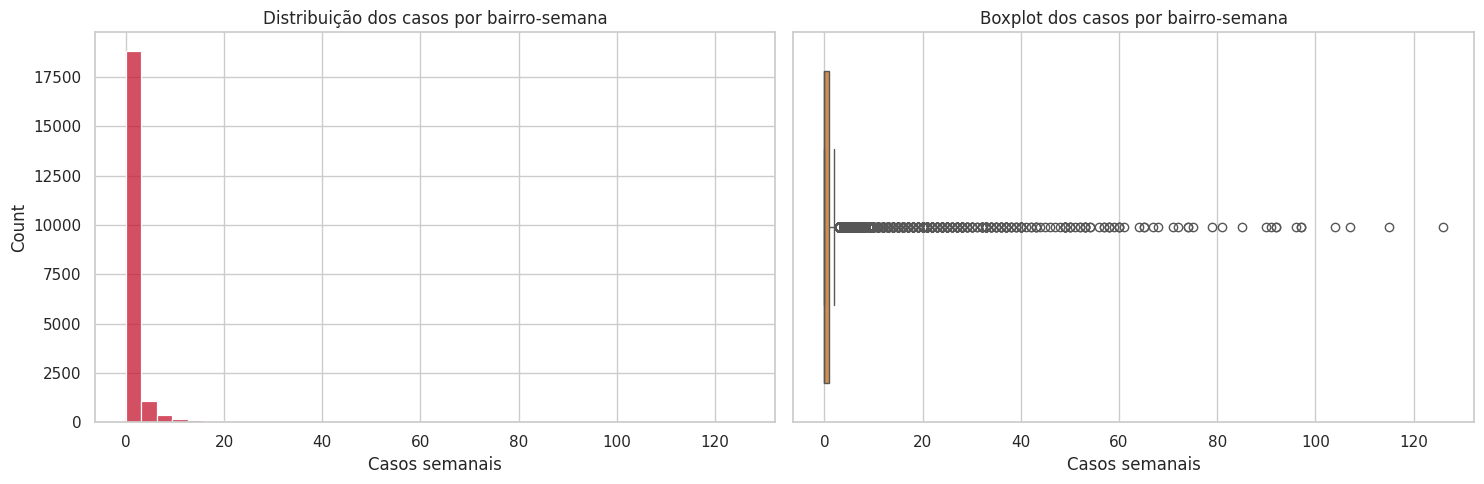

Limite superior pelo IQR: 2.50
Pontos sinalizados para investigação: 2,863
Decisão: manter esses pontos, pois picos epidemiológicos podem ser eventos reais.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(base["CASOS_SEMANAIS"], bins=40, ax=axes[0], color="#c5162e")
axes[0].set_title("Distribuição dos casos por bairro-semana")
axes[0].set_xlabel("Casos semanais")

sns.boxplot(x=base["CASOS_SEMANAIS"], ax=axes[1], color="#e58f3c")
axes[1].set_title("Boxplot dos casos por bairro-semana")
axes[1].set_xlabel("Casos semanais")
plt.tight_layout()
plt.show()

q1, q3 = base["CASOS_SEMANAIS"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
potenciais_outliers = base[base["CASOS_SEMANAIS"] > limite_superior]
print(f"Limite superior pelo IQR: {limite_superior:.2f}")
print(f"Pontos sinalizados para investigação: {len(potenciais_outliers):,}")
print("Decisão: manter esses pontos, pois picos epidemiológicos podem ser eventos reais.")

**14.2 Pergunta: em quais anos e meses os registros se concentram?**

Gráfico de barras compara anos; linha mensal evidencia sazonalidade. O resultado ajuda a contar quando a pressão epidemiológica costuma aumentar.

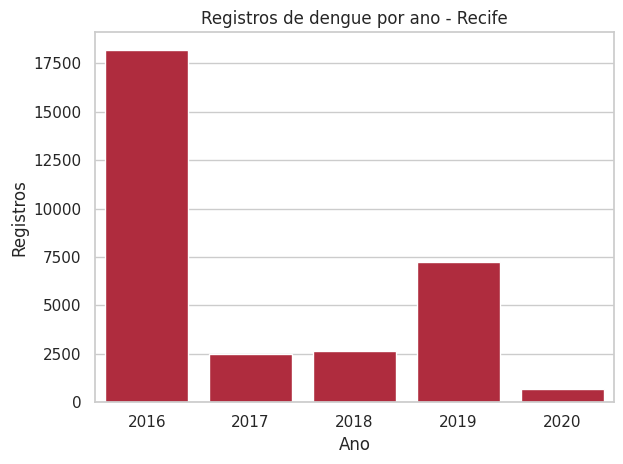

In [18]:
casos_ano = base.groupby("ANO", as_index=False)["CASOS_SEMANAIS"].sum()
sns.barplot(data=casos_ano, x="ANO", y="CASOS_SEMANAIS", color="#c5162e")
plt.title("Registros de dengue por ano - Recife")
plt.xlabel("Ano")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

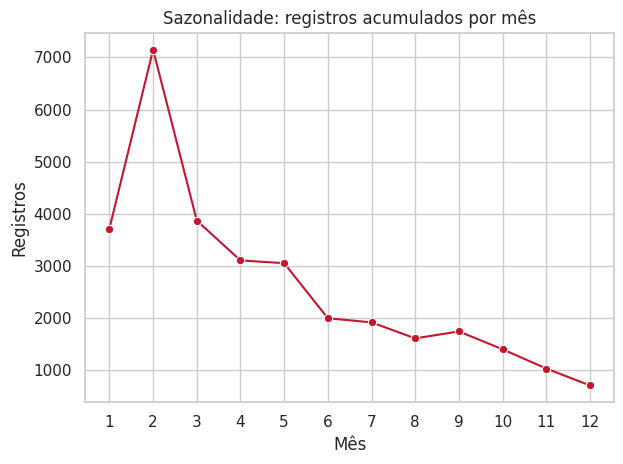

In [19]:
casos_mes = base.groupby("MES", as_index=False)["CASOS_SEMANAIS"].sum()
sns.lineplot(data=casos_mes, x="MES", y="CASOS_SEMANAIS", marker="o", color="#c5162e")
plt.title("Sazonalidade: registros acumulados por mês")
plt.xticks(range(1, 13))
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

**14.3 Pergunta: onde está a maior carga territorial?**

O total absoluto indica volume de demanda. A incidência corrige pela população e permite uma comparação mais justa entre bairros de tamanhos diferentes. As duas medidas respondem a perguntas complementares.

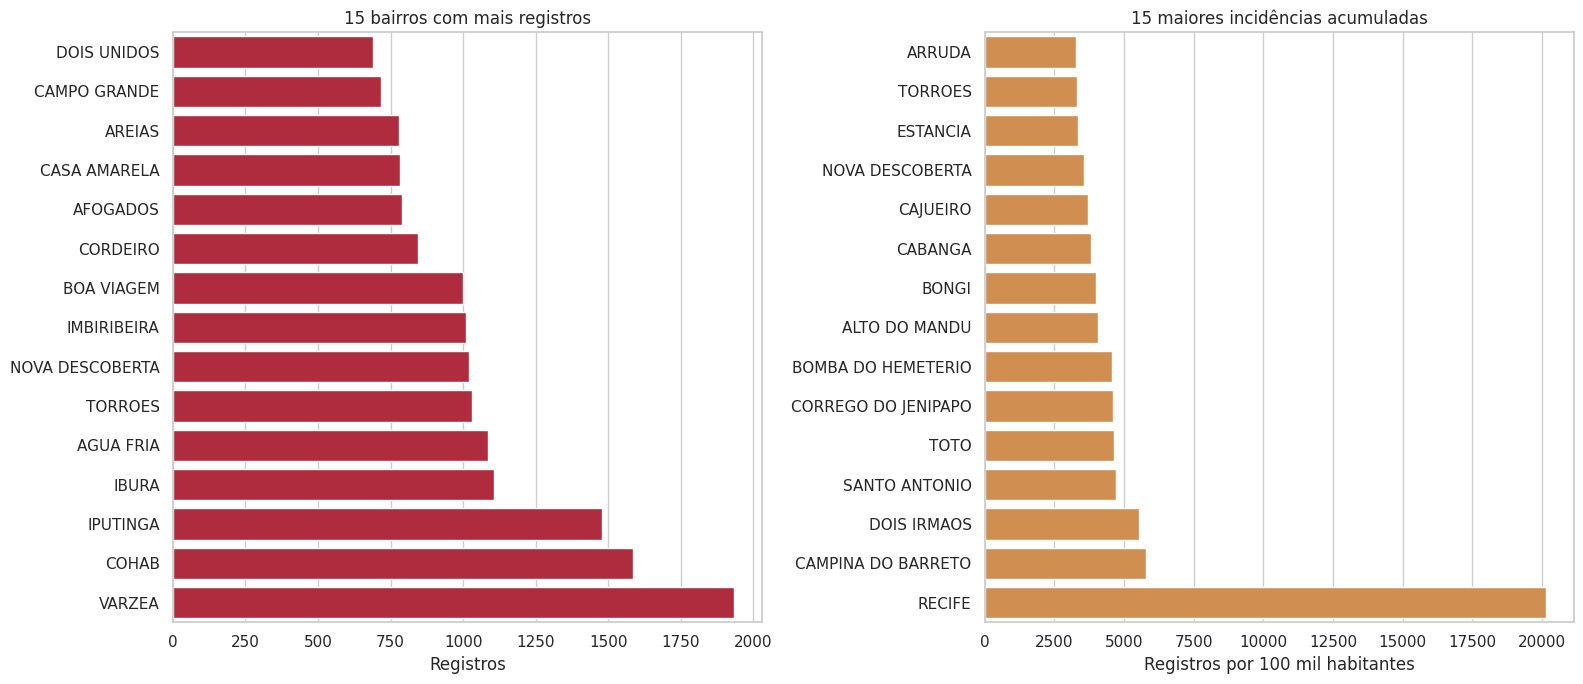

In [20]:
ranking = (
    base.groupby("BAIRRO", as_index=False)
    .agg(
        CASOS=("CASOS_SEMANAIS", "sum"),
        POPULACAO=("POPULACAO_2022", "first"),
    )
)
ranking["INCIDENCIA_ACUM_100MIL"] = ranking["CASOS"] / ranking["POPULACAO"] * 100_000

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_casos = ranking.nlargest(15, "CASOS").sort_values("CASOS")
sns.barplot(data=top_casos, y="BAIRRO", x="CASOS", ax=axes[0], color="#c5162e")
axes[0].set_title("15 bairros com mais registros")
axes[0].set_xlabel("Registros")
axes[0].set_ylabel("")

top_inc = ranking.replace([np.inf, -np.inf], np.nan).dropna().nlargest(15, "INCIDENCIA_ACUM_100MIL").sort_values("INCIDENCIA_ACUM_100MIL")
sns.barplot(data=top_inc, y="BAIRRO", x="INCIDENCIA_ACUM_100MIL", ax=axes[1], color="#e58f3c")
axes[1].set_title("15 maiores incidências acumuladas")
axes[1].set_xlabel("Registros por 100 mil habitantes")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**14.4 Pergunta: chuva, temperatura e umidade se relacionam com os casos?**

O scatter plot mostra a forma da relação chuva-casos. O heatmap resume a força das relações lineares. Valores próximos de zero significam pouca relação **linear contemporânea**, não ausência de qualquer relação.

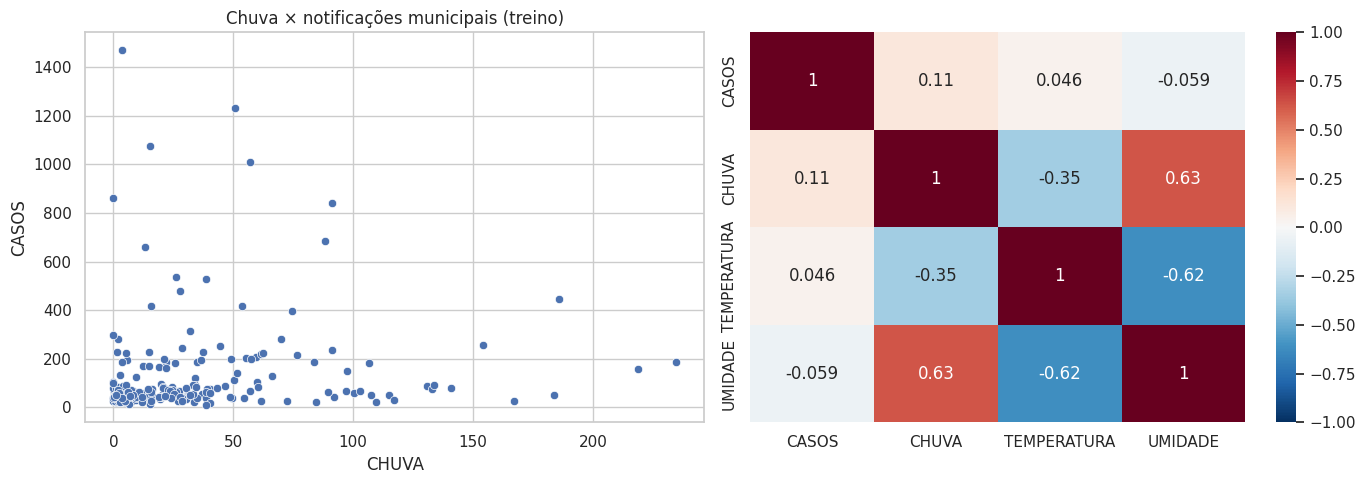

In [21]:
serie_recife = base.groupby("DATA_SEMANA").agg(
    CASOS=("CASOS_SEMANAIS", lambda s:s.sum(min_count=len(s))),
    CHUVA=("PRECIPITACAO_SEMANAL_MM", "first"),
    TEMPERATURA=("TEMPERATURA_MEDIA_C", "first"), UMIDADE=("UMIDADE_MEDIA_PCT", "first"))
# Reindexar inclui semanas sem cobertura como ausentes, nunca zeros.
serie_recife = serie_recife.reindex(pd.date_range(serie_recife.index.min(),serie_recife.index.max(),freq="W-MON"))
fig, axes = plt.subplots(1,2,figsize=(14,5))
sns.scatterplot(data=serie_recife,x="CHUVA",y="CASOS",ax=axes[0])
sns.heatmap(serie_recife.corr(),annot=True,vmin=-1,vmax=1,center=0,cmap="RdBu_r",ax=axes[1])
axes[0].set_title("Chuva × notificações municipais (treino)")
plt.tight_layout(); plt.show()

**Defasagens entre clima e casos**

Esta análise verifica se o clima de uma semana apresenta associação com os casos registrados de uma a quatro semanas depois. Correlação não prova causalidade, mas ajuda a identificar defasagens úteis para a AV2.

,variavel_climatica,casos_semanas_depois,correlacao,pares_validos
0,CHUVA,0,0.109648,203
1,CHUVA,1,0.120051,202
2,CHUVA,2,0.152244,201
3,CHUVA,3,0.103012,200
4,CHUVA,4,0.132200,199
5,TEMPERATURA,0,0.045901,203
6,TEMPERATURA,1,0.058590,202
7,TEMPERATURA,2,0.044922,201
8,TEMPERATURA,3,0.057094,200
9,TEMPERATURA,4,0.056469,199


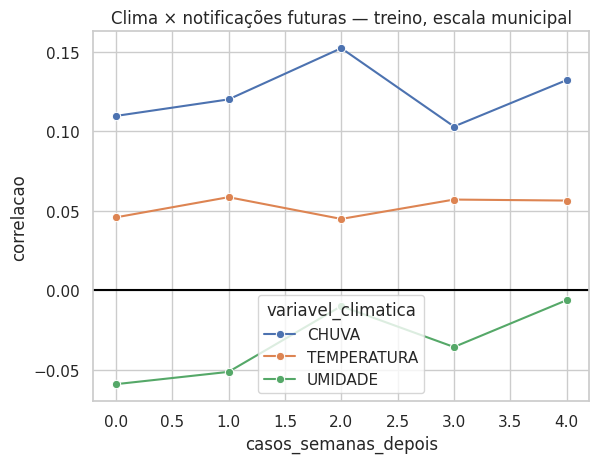

CASOS     CHUVA  TEMPERATURA   UMIDADE
ANO                                                        
2016 CASOS        1.000000  0.227120     0.344463 -0.434221
     CHUVA        0.227120  1.000000    -0.042156  0.291177
     TEMPERATURA  0.344463 -0.042156     1.000000 -0.820122
     UMIDADE     -0.434221  0.291177    -0.820122  1.000000
2017 CASOS        1.000000  0.028641     0.266165  0.240717
     CHUVA        0.028641  1.000000    -0.489737  0.769481
     TEMPERATURA  0.266165 -0.489737     1.000000 -0.501513
     UMIDADE      0.240717  0.769481    -0.501513  1.000000
2018 CASOS        1.000000  0.497795    -0.457955  0.643572
     CHUVA        0.497795  1.000000    -0.267585  0.696632
     TEMPERATURA -0.457955 -0.267585     1.000000 -0.682969
     UMIDADE      0.643572  0.696632    -0.682969  1.000000
2019 CASOS        1.000000  0.190543    -0.670442  0.332817
     CHUVA        0.190543  1.000000    -0.518150  0.695094
     TEMPERATURA -0.670442 -0.518150     1.000000 -0.647879
     UMIDADE      0.332817  0.695094    -0.647879  1.000000
2020 CASOS        1.000000  0.028136     0.348137 -0.502310
     CHUVA        0.028136  1.000000    -0.563224  0.483534
     TEMPERATURA  0.348137 -0.563224     1.000000 -0.743335
     UMIDADE     -0.502310  0.483534    -0.743335  1.000000

Não há teste de significância ou comprovação causal. Séries autocorrelacionadas e busca de vários lags exigem cautela.
Relações por bairro são exploratórias; muitos testes e autocorrelação impedem tratar o maior r como prova.


,count,median,min,max
variavel,,,,
PRECIPITACAO_SEMANAL_MM,465,0.077454,-0.105856,0.330337
TEMPERATURA_MEDIA_C,465,0.038296,-0.319182,0.203313
UMIDADE_MEDIA_PCT,465,-0.021557,-0.168176,0.286381


,CASOS,CHUVA,TEMPERATURA,UMIDADE
CASOS,1.000000,0.044055,-0.088177,-0.250305
CHUVA,0.044055,1.000000,-0.372751,0.427299
TEMPERATURA,-0.088177,-0.372751,1.000000,-0.416900
UMIDADE,-0.250305,0.427299,-0.416900,1.000000


In [22]:
linhas = []
for variavel in ["CHUVA", "TEMPERATURA", "UMIDADE"]:
    for atraso in range(5):
        pares = pd.concat([serie_recife[variavel], serie_recife.CASOS.shift(-atraso).rename("FUTURO")],axis=1).dropna()
        linhas.append({"variavel_climatica":variavel,"casos_semanas_depois":atraso,
                       "correlacao":pares[variavel].corr(pares.FUTURO),"pares_validos":len(pares)})
corr_lags = pd.DataFrame(linhas)
display(corr_lags)
sns.lineplot(data=corr_lags,x="casos_semanas_depois",y="correlacao",hue="variavel_climatica",marker="o")
plt.axhline(0,color="black");plt.title("Clima × notificações futuras — treino, escala municipal");plt.show()
corr_lags.to_csv(REPORT_DIR/"correlacoes_treino.csv",index=False)
# Verificar estabilidade entre anos: correlação agregada pode refletir sazonalidade comum.
por_ano = serie_recife.assign(ANO=serie_recife.index.year).groupby("ANO")[["CASOS","CHUVA","TEMPERATURA","UMIDADE"]].corr()
display(por_ano)
print("Não há teste de significância ou comprovação causal. Séries autocorrelacionadas e busca de vários lags exigem cautela.")
linhas_bairro = []
for bairro,g in base.groupby("BAIRRO"):
    g = g.set_index("DATA_SEMANA").reindex(serie_recife.index)
    for clima in ["PRECIPITACAO_SEMANAL_MM","TEMPERATURA_MEDIA_C","UMIDADE_MEDIA_PCT"]:
        for lag in range(5):
            pares = pd.concat([g[clima],g.CASOS_SEMANAIS.shift(-lag).rename("FUTURO")],axis=1).dropna()
            r = pares[clima].corr(pares.FUTURO) if len(pares)>=30 and pares[clima].nunique()>1 and pares.FUTURO.nunique()>1 else np.nan
            linhas_bairro.append({"BAIRRO":bairro,"variavel":clima,"defasagem":lag,"n_pares":len(pares),"r_pearson":r})
corr_bairros = pd.DataFrame(linhas_bairro)
corr_bairros.to_csv(REPORT_DIR/"correlacoes_por_bairro_treino.csv",index=False)
print("Relações por bairro são exploratórias; muitos testes e autocorrelação impedem tratar o maior r como prova.")
display(corr_bairros.groupby("variavel").r_pearson.agg(["count","median","min","max"]))
# Correlação após remover médias mensais: diagnóstico de sazonalidade comum, não identificação causal.
dessazonalizada = serie_recife - serie_recife.groupby(serie_recife.index.month).transform("mean")
display(dessazonalizada.corr())
dessazonalizada.corr().to_csv(REPORT_DIR/"correlacao_apos_media_mensal_treino.csv")

**14.6 EDA específica das novas features**
**Objetivo:** verificar se as variáveis criadas representam informação utilizável. Examinar ausências decorrentes de janelas completas, distribuições assimétricas, relações com o alvo e redundâncias. Correlação fraca isolada não elimina utilidade não linear.

**Interpretação a preencher após execução real:** quais janelas perdem mais dados? Há features redundantes? As relações se mantêm entre anos? Não selecionar features a partir do teste.

,ausentes_pct,mediana,min,max
CASOS_LAG_1,0.450450,0.000000,0.000000,126.000000
CASOS_LAG_2,0.900901,0.000000,0.000000,126.000000
CASOS_LAG_3,1.351351,0.000000,0.000000,126.000000
CASOS_LAG_4,1.801802,0.000000,0.000000,126.000000
MEDIA_CASOS_4S,1.801802,0.500000,0.000000,93.000000
CHUVA_4S_MM,18.918919,97.600000,1.800000,503.400000
SEMANA_SIN,0.000000,0.094471,-0.999999,0.999986
SEMANA_COS,0.000000,0.095637,-0.999979,1.000000
DENSIDADE_HAB_KM2,0.000000,11599.743891,203.536876,28489.325221
INCIDENCIA_100MIL,0.000000,0.000000,0.000000,2772.643253


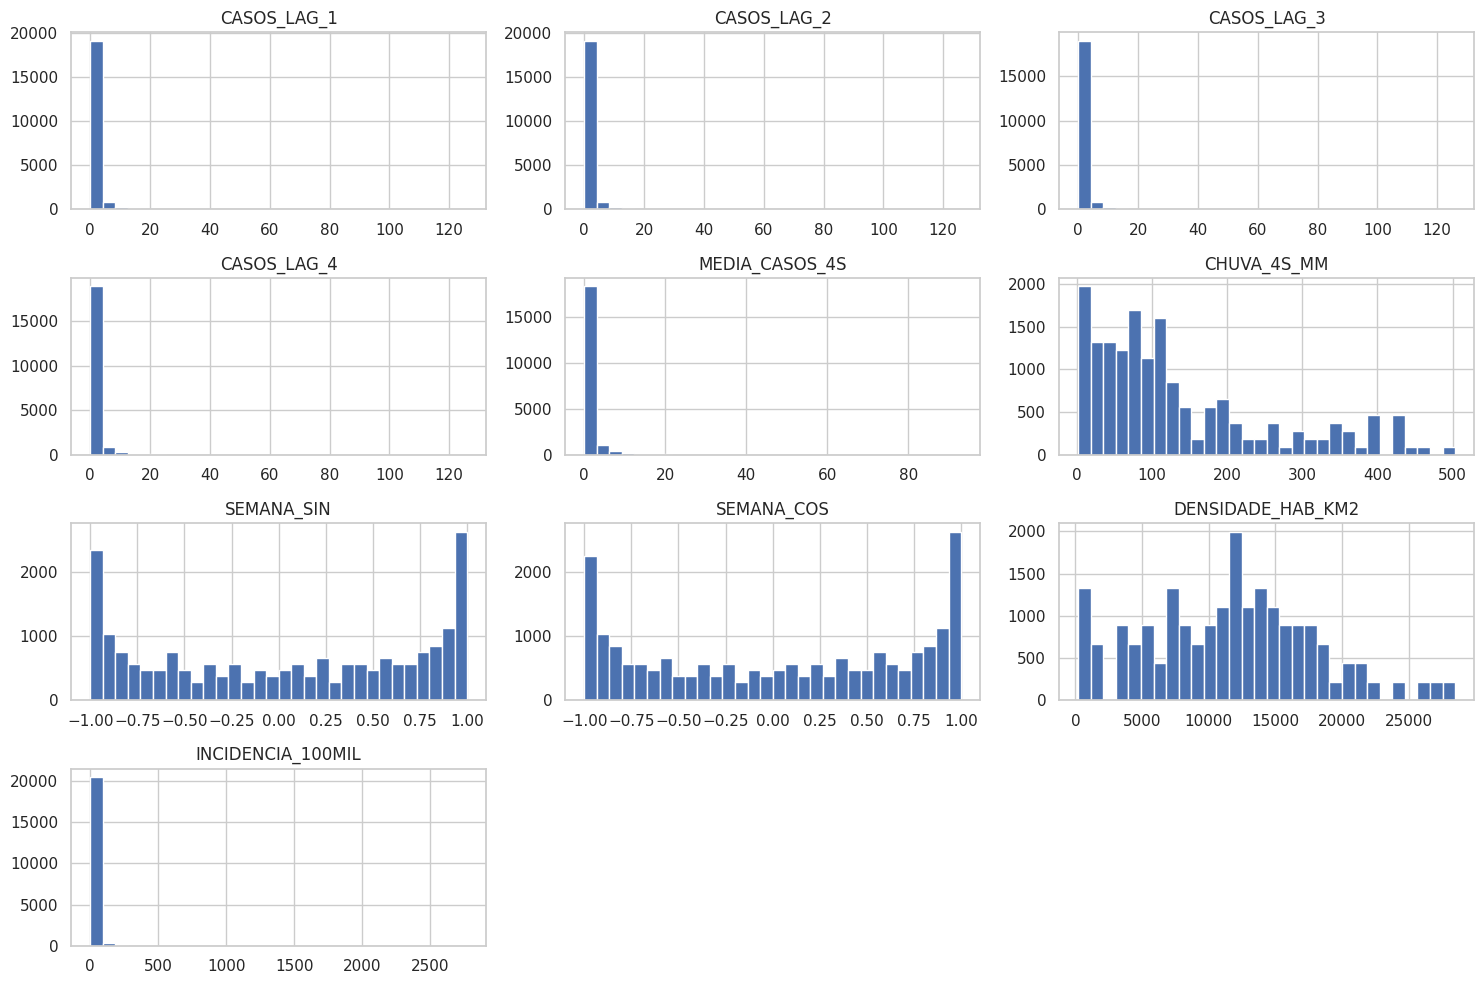

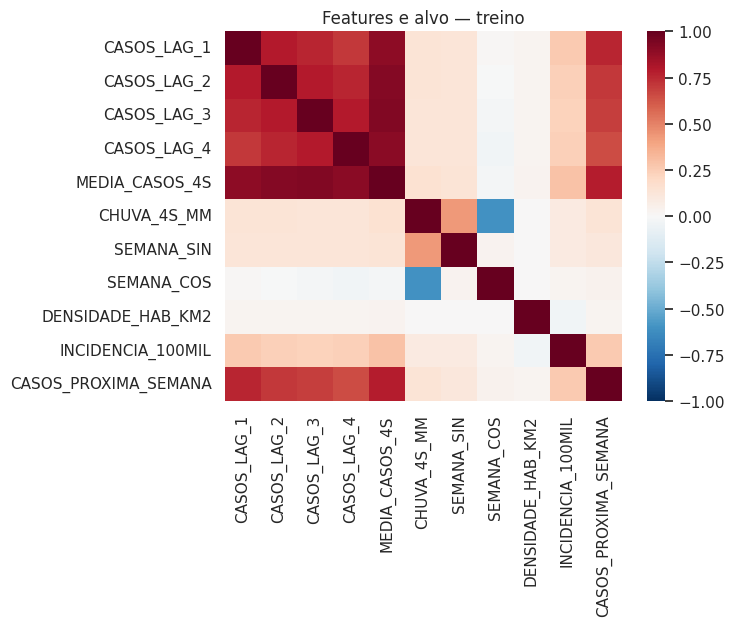

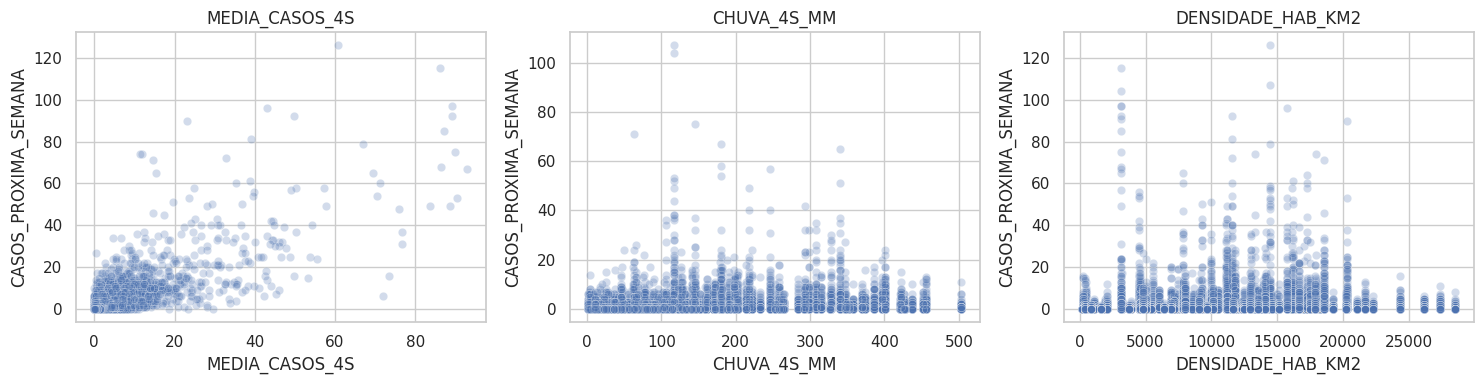

In [23]:
resumo_features = pd.DataFrame({"ausentes_pct":base[features_criadas].isna().mean()*100,
    "mediana":base[features_criadas].median(),"min":base[features_criadas].min(),"max":base[features_criadas].max()})
display(resumo_features)
base[features_criadas].hist(figsize=(15,10),bins=30);plt.tight_layout();plt.show()
sns.heatmap(base[features_criadas + ["CASOS_PROXIMA_SEMANA"]].corr(),cmap="RdBu_r",center=0,vmin=-1,vmax=1)
plt.title("Features e alvo — treino");plt.show()
resumo_features.to_csv(REPORT_DIR/"eda_features_treino.csv")
fig,axes = plt.subplots(1,3,figsize=(15,4))
for ax,c in zip(axes,["MEDIA_CASOS_4S","CHUVA_4S_MM","DENSIDADE_HAB_KM2"]):
    sns.scatterplot(data=base,x=c,y="CASOS_PROXIMA_SEMANA",alpha=.25,ax=ax)
    ax.set_title(c)
plt.tight_layout();plt.show()

## 15. Normalização, padronização e preparação para AV2
**Min-Max:** `(x − mínimo do treino)/(máximo − mínimo do treino)`. Em geral deixa o treino entre 0 e 1, mas valores futuros podem sair dessa faixa. Sensível a extremos.  
**StandardScaler:** `(x − média do treino)/desvio padrão do treino`. Centraliza e ajusta escala; não torna a distribuição normal e não elimina assimetria ou outliers.

Aplicamos e comparamos as duas alternativas às **entradas numéricas**, em pipelines separados. Não aplicamos uma após a outra. Não escalonamos alvo, datas, identificadores ou códigos de categoria. Imputação por mediana e codificação de categorias são aprendidas apenas no treino. Medianas são uma escolha inicial, a avaliar com a cobertura climática.

Para Poisson, a padronização ajuda a colocar entradas em escalas comparáveis; árvores e Random Forest serão avaliadas sem escala. Nesta AV1 demonstramos o pré-processamento, sem treinar ou escolher modelos. Incidência, mês, trimestre e período chuvoso ficam descritivos no conjunto inicial para reduzir redundância.

A incidência por 100 mil habitantes é uma medida territorial; ela não substitui o ajuste de escala das entradas do modelo.

,original,padronizado_media,padronizado_min,padronizado_max,normalizado_media,normalizado_min,normalizado_max
CASOS_SEMANAIS,1.162536,-2.313792e-16,-0.368729,30.397374,0.011985,0.0,1.0
CASOS_LAG_1,1.213914,-7.705595e-16,-0.364750,28.781288,0.012515,0.0,1.0
CASOS_LAG_2,1.290135,2.214467e-15,-0.347153,30.597329,0.011219,0.0,1.0
CASOS_LAG_3,1.362548,6.328956e-16,-0.330877,27.595324,0.011848,0.0,1.0
CASOS_LAG_4,1.465426,-2.954201e-15,-0.312429,26.550779,0.011630,0.0,1.0
MEDIA_CASOS_4S,1.333006,-2.968525e-16,-0.372048,25.584662,0.014333,0.0,1.0
CHUVA_4S_MM,132.946591,3.411420e-14,-1.122548,2.766885,0.288615,0.0,1.0
PRECIPITACAO_SEMANAL_MM,33.145455,2.293120e-14,-0.824882,5.013544,0.141285,0.0,1.0
TEMPERATURA_MEDIA_C,25.921894,4.768709e-13,-1.986927,1.860036,0.516492,0.0,1.0
UMIDADE_MEDIA_PCT,76.998316,-4.035965e-13,-2.078017,2.555371,0.448488,0.0,1.0


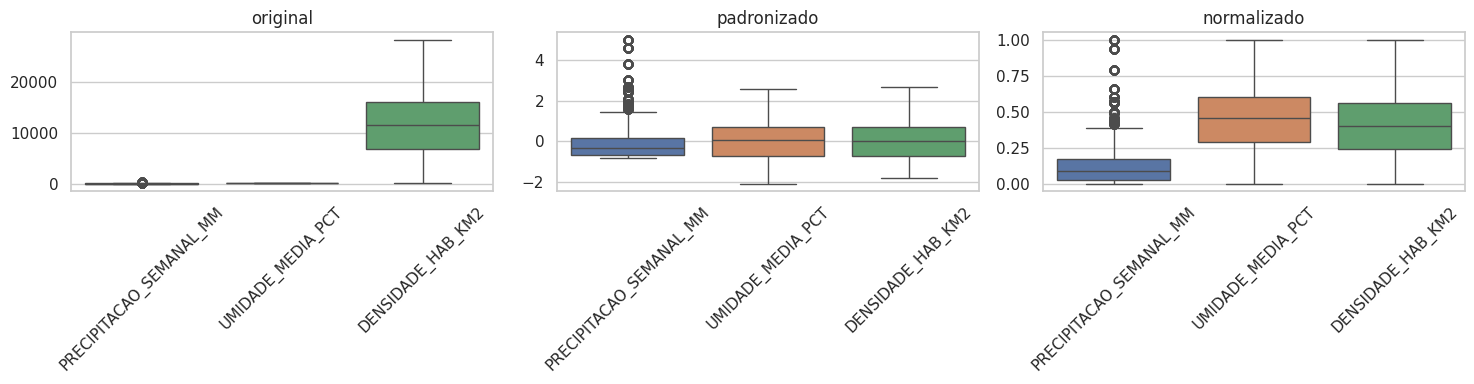

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import joblib

numericas = ["CASOS_SEMANAIS", "CASOS_LAG_1", "CASOS_LAG_2", "CASOS_LAG_3", "CASOS_LAG_4",
 "MEDIA_CASOS_4S", "CHUVA_4S_MM", "PRECIPITACAO_SEMANAL_MM", "TEMPERATURA_MEDIA_C", "UMIDADE_MEDIA_PCT",
 "POPULACAO_2022", "DENSIDADE_HAB_KM2", "SEMANA_SIN", "SEMANA_COS"]
categoricas = ["BAIRRO", "RPA"]
entradas = numericas + categoricas
X_treino = base_completa.loc[base_completa.CONJUNTO.eq("treino"), entradas].copy()
X_treino[categoricas] = X_treino[categoricas].fillna("AUSENTE").astype(str)
if X_treino[numericas].notna().sum().eq(0).any():
    raise ValueError("Há entrada numérica totalmente ausente no treino; rever fonte/cobertura antes de imputar.")
preprocessadores = {}
for nome, escalador in [("padronizado", StandardScaler()), ("normalizado", MinMaxScaler()), ("sem_escala", "passthrough")]:
    prep = ColumnTransformer([
        ("numericas", Pipeline([("imputacao", SimpleImputer(strategy="median",add_indicator=True)), ("escala", escalador)]), numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore",sparse_output=False), categoricas)], remainder="drop")
    prep.fit(X_treino)
    preprocessadores[nome] = prep
    joblib.dump(prep, DATA_DIR/f"preprocessador_{nome}.joblib")
    # Validação/teste serão transformados na AV2 usando transform, nunca fit_transform.

comparacao = pd.DataFrame({"original":X_treino[numericas].mean()})
for nome in ["padronizado", "normalizado"]:
    valores = preprocessadores[nome].transform(X_treino)[:, :len(numericas)]
    comparacao[nome + "_media"] = valores.mean(axis=0)
    comparacao[nome + "_min"] = valores.min(axis=0)
    comparacao[nome + "_max"] = valores.max(axis=0)
display(comparacao)
comparacao.to_csv(REPORT_DIR/"comparacao_escalas_treino.csv")
config = {"entradas_numericas":numericas,"entradas_categoricas":categoricas,"alvo":"CASOS_PROXIMA_SEMANA",
 "corte_validacao":str(corte1.date()),"corte_teste":str(corte2.date()),
 "intervalos_cobertura":INTERVALOS_COBERTURA_CONFIRMADA,"justificativa_cobertura":JUSTIFICATIVA_COBERTURA,"cobertura_minima_clima":COBERTURA_MINIMA_CLIMA,
 "nota":"Preprocessadores AV1 ajustados apenas no treino. Recriar dentro de cada fold temporal da AV2."}
(DATA_DIR/"config_av2.json").write_text(json.dumps(config,ensure_ascii=False,indent=2))
# Examinar valores individuais e dispersão, além da média.
comparacao["original_desvio"] = X_treino[numericas].std(ddof=0)
for nome in ["padronizado","normalizado"]:
    comparacao[nome+"_desvio"] = preprocessadores[nome].transform(X_treino)[:,:len(numericas)].std(axis=0)
comparacao.to_csv(REPORT_DIR/"comparacao_escalas_treino.csv")
fig,axes = plt.subplots(1,3,figsize=(15,4))
medidas_exemplo=["PRECIPITACAO_SEMANAL_MM","UMIDADE_MEDIA_PCT","DENSIDADE_HAB_KM2"]
for ax,nome in zip(axes,["original","padronizado","normalizado"]):
    valores = X_treino[numericas] if nome=="original" else pd.DataFrame(preprocessadores[nome].transform(X_treino)[:,:len(numericas)],columns=numericas)
    sns.boxplot(data=valores[medidas_exemplo],ax=ax)
    ax.set_title(nome);ax.tick_params(axis="x",rotation=45)
plt.tight_layout();plt.show()

## 16. Principais descobertas

Esta célula transforma os resultados em uma narrativa automática, evitando encerrar a EDA apenas com gráficos.

In [25]:
print("RESUMO REAL — DADOS ANTERIORES AO CORTE DE VALIDAÇÃO")
print("Linhas lidas nas fontes:",len(dengue))
print("Registros após limpeza:",len(df_limpo))
print("Registros no painel coberto de análise:",int(base.CASOS_SEMANAIS.sum()))
print("Bairros:",base.BAIRRO.nunique())
print("Período de EDA:",base.DATA_SEMANA.min().date(),"a",base.DATA_SEMANA.max().date())
print("Hipótese de cobertura:",JUSTIFICATIVA_COBERTURA)
print("Maior volume por ano na EDA:",casos_ano.loc[casos_ano.CASOS_SEMANAIS.idxmax()].to_dict())
print("Maior volume por bairro na EDA:",ranking.loc[ranking.CASOS.idxmax(),["BAIRRO","CASOS"]].to_dict())
print("Maior associação linear em módulo na EDA:")
display(corr_lags.loc[corr_lags.correlacao.abs().idxmax()].to_frame("resultado"))
print("Associação exploratória; não demonstra causalidade nem desempenho preditivo. O teste final foi reservado.")
summary = {"linhas_lidas":len(dengue),"registros_limpos":len(df_limpo),"notificacoes_treino":int(base.CASOS_SEMANAIS.sum()),
 "inicio_eda":str(base.DATA_SEMANA.min().date()),"fim_eda":str(base.DATA_SEMANA.max().date()),
 "corte_validacao":str(corte1.date()),"corte_teste":str(corte2.date()),
 "correlacoes":corr_lags.to_dict("records"),"qualidade_por_ano":qualidade_ano.reset_index().to_dict("records"),
 "conjuntos":base_completa.groupby("CONJUNTO").size().to_dict(),"ids_divergentes":int(conflitos.sum())}
(REPORT_DIR/"resumo_execucao_real.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2))

RESUMO REAL — DADOS ANTERIORES AO CORTE DE VALIDAÇÃO
Linhas lidas nas fontes: 71663
Registros após limpeza: 71176
Registros no painel coberto de análise: 31219
Bairros: 94
Período de EDA: 2016-01-04 a 2020-03-30
Hipótese de cobertura: Hipótese operacional: recursos oficiais anuais históricos de 2016–2025 representam o período anual de notificações publicado. Não comprova ausência de subnotificação ou falhas do sistema. Zeros significam ausência de registro na fonte sob essa hipótese. Foram conferidos registros de 2025 até 31/12/2025; não é garantia de completude de vigilância.
Maior volume por ano na EDA: {'ANO': 2016.0, 'CASOS_SEMANAIS': 18185.0}
Maior volume por bairro na EDA: {'BAIRRO': 'VARZEA', 'CASOS': 1934.0}
Maior associação linear em módulo na EDA:


,resultado
variavel_climatica,CHUVA
casos_semanas_depois,2
correlacao,0.152244
pares_validos,201


Associação exploratória; não demonstra causalidade nem desempenho preditivo. O teste final foi reservado.


4397

**Limitações e passagem para AV2**
- Notificações não equivalem automaticamente a casos confirmados; classificação final ainda deve ser discutida.
- Atrasos e revisões retrospectivas não reproduzem a disponibilidade dos dados em tempo real.
- Cobertura declarada deve ser conferida nas fontes; semanas incompletas ficam sem contagem válida.
- População fixa de 2022 e uma única estação climática limitam inferências históricas e hiperlocais.
- A chuva com cobertura ≥90% permanece soma observada; não estimamos o volume das horas ausentes.
- Correlações municipais não comprovam relações em cada bairro. Sazonalidade comum pode influenciar os resultados.
- IDs repetidos entre arquivos anuais precisam de revisão: o mesmo número isolado não garante identidade do evento. Registros analiticamente divergentes com ID repetido são preservados e relatados.
- Cortes temporais iniciais devem ser avaliados frente a anos epidêmicos e cobertura antes dos experimentos.

**Critério de conclusão:** executar com as fontes reais, revisar relatórios de qualidade e cobertura, interpretar EDA das features, conferir os conjuntos e somente então iniciar os modelos. A execução real e a revisão das saídas estão registradas nesta versão. A definição final das classificações, a sensibilidade dos IDs e a atualização dos slides continuam sendo decisões científicas pendentes.
- A coorte inicial da AV2 exige clima e histórico completos. Relatar exclusões e fazer análise de sensibilidade antes de generalizar para períodos sem clima.

## 17. Exportação da base revisada

In [26]:
base_final = base_completa.copy()
assert not base_final.duplicated(["BAIRRO", "DATA_SEMANA"]).any()
assert base_final.loc[~base_final.COBERTURA_DENGUE, "CASOS_SEMANAIS"].isna().all()
assert base_final.loc[base_final.CONJUNTO.isin(["treino","validacao","teste"]), "CASOS_PROXIMA_SEMANA"].notna().all()
caminho_saida = DATA_DIR / "dataset_av1_revisado.csv"
base_final.to_csv(caminho_saida,index=False,encoding="utf-8-sig")
colunas = pd.DataFrame({"variavel":base_final.columns,"dtype":base_final.dtypes.astype(str).values,
                        "ausentes":base_final.isna().sum().values,"percentual_ausente":base_final.isna().mean().values*100})
colunas.to_csv(REPORT_DIR/"dicionario_tipos_ausencias.csv",index=False)
print("Base exportada:", caminho_saida, base_final.shape)
print("Escala original preservada; pipelines de escala são separados e ajustados só no treino.")
import importlib.metadata as metadata
versoes = {nome:metadata.version(nome) for nome in ["pandas","numpy","matplotlib","seaborn","scikit-learn","openpyxl","joblib"]}
manifesto = {"inicio_utc":RUN_INICIO,"fim_utc":datetime.now(timezone.utc).isoformat(),"python":platform.python_version(),
 "versoes":versoes,"fontes":EXECUCAO_FONTES,"cobertura":INTERVALOS_COBERTURA_CONFIRMADA,
 "justificativa_cobertura":JUSTIFICATIVA_COBERTURA,"linhas_painel":len(base_final),
 "colunas":len(base_final.columns),"status":"executado_com_entradas_fornecidas_revisar_interpretacao"}
(DATA_DIR/"manifesto_execucao.json").write_text(json.dumps(manifesto,ensure_ascii=False,indent=2))
print("Execução técnica concluída. Confirmar origem das entradas e interpretar resultados antes de declarar AV1 encerrada.")
# Acrescentar significado, papel e unidade ao dicionário automático.
descricoes = {
 "BAIRRO":("Bairro de residência padronizado","categoria","Recife/IBGE"),
 "RPA":("Região Político-Administrativa","categoria","Prefeitura"),
 "DATA_SEMANA":("Segunda-feira da semana civil local","data","derivada da notificação"),
 "ANO":("Ano ISO da semana civil, não ano do arquivo","ano","calendário"),
 "SEMANA":("Número ISO da semana civil","semana","calendário"),
 "COBERTURA_DENGUE":("Sete dias dentro da hipótese operacional de cobertura da fonte anual","booleano","configuração"),
 "REGISTROS_OBSERVADOS":("Notificações encontradas antes de validar cobertura semanal","registros","Recife"),
 "CASOS_SEMANAIS":("Notificações na semana t; nome legado não implica confirmação","registros","Recife"),
 "POPULACAO_2022":("População fixa de referência","habitantes","IBGE 2022"),
 "AREA_KM2_IBGE":("Área territorial do bairro","km²","IBGE 2022"),
 "DENSIDADE_HAB_KM2":("População dividida pela área","habitantes/km²","derivada"),
 "INCIDENCIA_100MIL":("Notificações/população multiplicado por 100.000","registros/100 mil hab.","derivada"),
 "PRECIPITACAO_SEMANAL_MM":("Soma observada da precipitação na semana t","mm","INMET A301"),
 "TEMPERATURA_MEDIA_C":("Média horária das temperaturas válidas na semana t","°C","INMET A301"),
 "UMIDADE_MEDIA_PCT":("Média horária da umidade válida na semana t","%","INMET A301"),
 "CHUVA_4S_MM":("Soma das quatro semanas t−3 a t, todas válidas","mm","derivada do INMET"),
 "MEDIA_CASOS_4S":("Média das quatro semanas t−4 a t−1, todas válidas","registros/semana","derivada"),
 "MES":("Mês da segunda-feira de referência","mês","calendário"),
 "TRIMESTRE":("Trimestre da segunda-feira de referência","trimestre","calendário"),
 "PERIODO_CHUVOSO":("Indicador descritivo março–agosto; regra a justificar","0/1","regra herdada"),
 "SEMANA_SIN":("Seno do ciclo anual pelo dia do ano","adimensional","calendário"),
 "SEMANA_COS":("Cosseno do ciclo anual pelo dia do ano","adimensional","calendário"),
 "CASOS_PROXIMA_SEMANA":("Notificações na semana t+1 do mesmo bairro","registros","alvo derivado"),
 "DATA_ALVO":("Segunda-feira da semana prevista t+1","data","calendário"),
 "ELEGIVEL_AV2":("Alvo, histórico e clima disponíveis na coorte comum","booleano","controle"),
 "CONJUNTO":("Treino, validação, teste ou fora da coorte","categoria","controle temporal"),
}
for k in range(1,5): descricoes[f"CASOS_LAG_{k}"]=(f"Notificações do bairro em t−{k}","registros","derivada")
for variavel in ["CHUVA","TEMPERATURA","UMIDADE"]:
    descricoes[f"HORAS_{variavel}"]=(f"Horas válidas de {variavel.lower()} na semana","horas","INMET A301")
    descricoes[f"COBERTURA_{variavel}"]=(f"Horas válidas de {variavel.lower()} divididas por 168","fração 0–1","derivada do INMET")
assert set(base_final.columns).issubset(descricoes), "Completar o dicionário para novas colunas."
dic = colunas.copy()
for j,campo in enumerate(["descricao","unidade","origem"]): dic[campo]=dic.variavel.map(lambda x:descricoes[x][j])
dic["papel"] = dic.variavel.map(lambda x:"alvo" if x=="CASOS_PROXIMA_SEMANA" else "entrada candidata" if x in entradas else "controle/descritiva")
dic["tipo_conceitual"] = dic.variavel.map(lambda x:"categórica nominal" if x in ["BAIRRO","RPA","CONJUNTO"] else "data" if x in ["DATA_SEMANA","DATA_ALVO"] else "binária" if x.startswith("ELEGIVEL") or x in ["COBERTURA_DENGUE","PERIODO_CHUVOSO"] else "numérica")
dic.to_csv(REPORT_DIR/"dicionario_completo.csv",index=False)


Base exportada: /content/dados_av1_revisada/dataset_av1_revisado.csv (49162, 36)
Escala original preservada; pipelines de escala são separados e ajustados só no treino.
Execução técnica concluída. Confirmar origem das entradas e interpretar resultados antes de declarar AV1 encerrada.


**17.1 Download opcional**

No Colab, execute a célula abaixo somente quando quiser salvar uma cópia local do CSV. Fora do Colab, ela apenas informa onde o arquivo foi gravado.

In [27]:
print("Base e relatórios disponíveis em:", DATA_DIR.resolve())
print("No Colab, abra o painel Arquivos para baixar as saídas. O notebook já contém os gráficos e tabelas desta execução.")

Base e relatórios disponíveis em: /content/dados_av1_revisada
No Colab, abra o painel Arquivos para baixar as saídas. O notebook já contém os gráficos e tabelas desta execução.


## 18. Conclusão da execução real e passagem para AV2
As 27 células de código foram executadas em ordem com fontes oficiais, em Python/IPython local, sem dados sintéticos. As saídas foram salvas neste notebook para consulta no Colab. Isso verifica a execução desta versão; uma nova execução depende do acesso às fontes e das dependências do ambiente.

**Dados e qualidade.** Foram adquiridas 71.663 linhas de recursos anuais de 2016–2025. A limpeza removeu 3 cópias analiticamente idênticas com ID presente e 484 registros com data ou bairro inválidos, restando 71.176 registros. Os 789 IDs com valores divergentes foram preservados e relatados, pois o identificador isolado não comprova unicidade. A contagem não representa pessoas ou episódios únicos. A integração entre IBGE e Prefeitura foi corrigida para Sítio dos Pintos; os demais nomes fora da malha estão no relatório territorial.

**Recorte da análise.** O painel tem 94 bairros. A EDA abrange semanas de 04/01/2016 a 30/03/2020; validação e teste foram reservados para a AV2. Os recursos anuais até 2025 foram adquiridos, mas isso não significa que a análise climática ou os conjuntos de modelagem cubram todos esses anos. Os zeros usam a hipótese operacional descrita na seção 11.

**Resposta encontrada.** No recorte de treino, as associações lineares municipais entre clima e notificações são fracas. A maior entre os 15 pares explorados é chuva com notificações duas semanas depois, aproximadamente r = 0,15. Ela varia entre anos; ao remover médias mensais, a correlação contemporânea chuva–notificações cai de aproximadamente 0,11 para 0,05. Não foi realizado teste de significância com ajuste para autocorrelação e múltiplas comparações. Esses resultados não comprovam causalidade, associação forte ou ganho de previsão. A pergunta da AV2 permanece: acrescentar clima melhora a previsão temporal em relação ao histórico sozinho?

**Features e escalas.** Defasagens e janelas são calculadas em calendário contínuo por bairro; janelas incompletas ficam ausentes. Chuva acumulada tem lacunas relevantes, relatadas na EDA. Normalização Min-Max e padronização foram demonstradas em alternativas separadas, aprendidas apenas no treino. As médias padronizadas ficam próximas de zero e os desvios próximos de um; Min-Max fica entre zero e um no treino. Isso não elimina assimetria nem outliers. Árvores também terão alternativa sem escala.

**Clima e cortes.** A execução utiliza medições A301 de 2016–2021 com limiar semanal de 90% por variável. A verificação separada dos arquivos 2022 e 2023 encontrou as três medidas vazias; ausência não virou chuva zero. Os cortes iniciais de semana-alvo são 13/04/2020 e 04/01/2021, com uma semana de intervalo entre conjuntos. Para a AV2, recriar os preprocessadores dentro de cada partição temporal e manter a mesma coorte na comparação com e sem clima.

**Pendências científicas.** Decidir a seleção por classificação final; avaliar sensibilidade a IDs ambíguos e revisões retrospectivas; atualizar slides e justificar a representatividade do período com clima. O resultado atual é sobre registros publicados nos recursos de dengue, não casos confirmados nem desempenho de um sistema operacional. Os modelos e seus resultados serão produzidos na AV2.
